# Tiền xử lý dữ liệu cho bài toán dự đoán giá ô tô

**Mục tiêu đề tài:** dự đoán **giá bán (triệu đồng)** của xe ô tô từ các đặc trưng: hãng, dòng xe, năm sản xuất, số km, hộp số, nhiên liệu, kiểu dáng, số chỗ, xuất xứ, tình trạng. Đây là bài toán **hồi quy có giám sát**.

**Đầu vào:** `raw_data_oto.csv` (dữ liệu crawl từ Chợ Tốt) &nbsp;→&nbsp; **Đầu ra:** `preprocess_data.csv`

**Vị trí trong quy trình:**

```
raw_data_oto.csv → preprocess_data.ipynb → preprocess_data.csv
                 → process_data.ipynb (chia train/test, fit trên train) → train_data.csv + test_data.csv
                 → model.ipynb (mã hóa, huấn luyện, đánh giá)
```

**Notebook này chỉ làm những bước không học tham số nào từ dữ liệu**: xử lý từng dòng độc lập, hoặc dùng ngưỡng cứng từ hiểu biết thực tế. Các bước học thống kê từ dữ liệu (điền thiếu bằng trung vị / mode, gộp nhãn hiếm theo tần suất, lọc giá đặt cọc theo trung vị giá) được chuyển sang `process_data.ipynb`, làm **sau** khi chia train/test và chỉ học từ train. Vì vậy file xuất ra **còn giá trị thiếu** ở `mileage_km` (xe đã dùng), `cartype`, `carseats`.

Mỗi bước đều có phần *vì sao xử lý như vậy*:

0. Dữ liệu được thu thập như thế nào và hệ quả cho tiền xử lý
1. Đọc dữ liệu và khám phá ban đầu
2. Chuẩn hóa kiểu dữ liệu và giá trị giả (`N/A`, `Đang cập nhật`, `Khác`) thành thiếu thật
3. Trích vị trí từ URL, loại cột vô ích và dòng trùng lặp
4. Phân tích giá trị thiếu
5. Phát hiện giá trị bất hợp lý theo quy tắc cứng (giá, giá giả `123.456.789`, số km, tình trạng "Mới" sai) và ngoại lệ
6. Điền giá trị thiếu bằng **hằng số** (km xe mới = 0, xuất xứ "Không rõ")
7. EDA: phân tích khám phá
8. Biến đổi log giá, tuổi xe (làm ở đây); gộp nhãn hiếm và các đặc trưng phụ thuộc số km đã điền (làm ở `process_data.ipynb`)
9. Mất cân bằng theo phân khúc giá và các quyết định cho bước sau
10. Kiểm tra cuối và xuất file

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from report_utils import SLIDE_RC, save_slide, save_table, start_tables, update_numbers, vn

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9aa0a6"
CURRENT_YEAR = 2026
RANDOM_STATE = 42

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
start_tables("preprocess")                 # xóa bảng Markdown cũ của notebook này trong tables/bang_bao_cao.md


def save(fig, name):
    # Lưu biểu đồ để đưa vào báo cáo (200 dpi)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 0. Dữ liệu được thu thập như thế nào và hệ quả cho tiền xử lý

Dữ liệu do `crawl_data.ipynb` thu thập ngày **25/10/2026**: duyệt 750 trang danh sách mới nhất của `xe.chotot.com/mua-ban-oto`, vào từng tin, đọc các thẻ HTML có thuộc tính `itemprop` (riêng giá đọc từ thẻ `name="price"`). Hiểu **cách dữ liệu được tạo ra** giúp biết mỗi kiểu lỗi đến từ đâu và nên xử lý thế nào.

**Từ điển dữ liệu**

| Cột | Ý nghĩa | Người bán nhập thế nào | Kiểu sau xử lý |
|---|---|---|---|
| `mileage_v2` → `mileage_km` | Số km đã đi | **gõ tự do** (dạng `109.366`) | số |
| `carorigin` | Xuất xứ | chọn từ danh sách (11 giá trị), không bắt buộc | phân loại |
| `condition_ad` | Tình trạng (Mới / Đã sử dụng) | chọn từ danh sách | phân loại |
| `veh_warranty_policy` | Chính sách bảo hành | | bỏ (một giá trị duy nhất) |
| `carbrand` | Hãng | chọn từ danh sách | phân loại |
| `carmodel` | Dòng xe | chọn từ danh sách theo hãng | phân loại |
| `mfdate` | Năm sản xuất | chọn từ danh sách (có mục "trước năm 1980") | số |
| `gearbox` | Hộp số | chọn từ danh sách (3 giá trị) | phân loại |
| `fuel` | Nhiên liệu | chọn từ danh sách (4 giá trị) | phân loại |
| `cartype` | Kiểu dáng | chọn từ danh sách (9 giá trị), không bắt buộc | phân loại |
| `carseats` | Số chỗ | chọn từ danh sách (có mục "Khác"), không bắt buộc | số |
| `price` | Giá rao bán (đồng) | **gõ tự do** | biến mục tiêu |
| `url` | Đường dẫn tin | sinh tự động, chứa quận/huyện và tỉnh | trích `province` (tỉnh/thành, dạng slug) rồi bỏ |

*"Chọn từ danh sách"* được suy ra từ dữ liệu: các cột này chỉ có một tập nhỏ giá trị cố định, viết thống nhất, không có lỗi chính tả.

**Cơ chế thu thập và hệ quả**

| Cơ chế trong code crawl | Hệ quả | Cách xử lý |
|---|---|---|
| Không tìm thấy thẻ của một thuộc tính (người bán bỏ trống, trang không hiển thị) → ghi chuỗi `"N/A"` | `"N/A"` = **thiếu thật**. Pandas mặc định tự đổi `"N/A"` thành NaN khi đọc, làm mất dấu vết nguồn gốc | Đọc với `keep_default_na=False` để thấy rõ từng loại giá trị giả, rồi tự đổi về NaN (mục 2) |
| Trang hiển thị `"Đang cập nhật"` khi người bán không chọn xuất xứ | cũng là thiếu thật | đổi về NaN |
| Cột chọn từ danh sách có sẵn mục `"Khác"`, `"Dòng khác"`, `"Kiểu dáng khác"`, `"Nước khác"` | là **lựa chọn thật** của người bán, không phải thiếu | giữ làm nhãn (riêng `carseats = "Khác"` không đổi ra số được → thiếu) |
| Số km và giá là **ô gõ tự do** | nguồn lỗi chính: gõ thiếu/thừa số 0, gõ km theo nghìn, ghi tiền trả trước, giá giả `123.456.789` | quy tắc kiểm tra ở mục 5 |
| Xe "Mới" không có ô số km | km thiếu ở **mọi** xe mới (mục 4) | điền 0 km |
| Bỏ qua URL đã gặp (kể cả tin "ưu tiên" lặp lại ở đầu mọi trang) | mỗi dòng là một **tin khác nhau**; dòng trùng nội dung là tin đăng lại hoặc đại lý đăng nhiều xe cùng cấu hình | loại trùng theo nội dung (mục 3) |
| `veh_warranty_policy` đọc ra `"Bảo hành hãng"` ở cả 14.835 tin | không phân biệt được tin nào, nhiều khả năng là giá trị mặc định của trang | bỏ cột |
| URL dạng `mua-ban-oto-<quận/huyện>-<tỉnh>/<mã tin>.htm` | có thông tin vị trí mà các cột khác không có | trích tỉnh/thành (mục 3); không tách quận/huyện vì quá thưa |
| Một lần thu thập, 750 trang tin mới nhất | ảnh chụp thị trường tại một thời điểm; giá là **giá rao**, không phải giá bán được | tuổi xe tính theo năm 2026; ghi rõ hạn chế trong báo cáo |

In [2]:
# Từ điển dữ liệu dạng bảng (cho slide / báo cáo)
DICT = [
    ("mileage_v2 → mileage_km", "Số km đã đi", "gõ tự do (dạng 109.366)", "số"),
    ("carorigin", "Xuất xứ", "chọn từ danh sách (11 giá trị), không bắt buộc", "phân loại"),
    ("condition_ad", "Tình trạng (Mới / Đã sử dụng)", "chọn từ danh sách", "phân loại"),
    ("veh_warranty_policy", "Chính sách bảo hành", "một giá trị duy nhất", "bỏ"),
    ("carbrand", "Hãng", "chọn từ danh sách", "phân loại"),
    ("carmodel", "Dòng xe", "chọn từ danh sách theo hãng", "phân loại"),
    ("mfdate", "Năm sản xuất", "chọn từ danh sách (có \"trước năm 1980\")", "số"),
    ("gearbox", "Hộp số", "chọn từ danh sách (3 giá trị)", "phân loại"),
    ("fuel", "Nhiên liệu", "chọn từ danh sách (4 giá trị)", "phân loại"),
    ("cartype", "Kiểu dáng", "chọn từ danh sách (9 giá trị), không bắt buộc", "phân loại"),
    ("carseats", "Số chỗ", "chọn từ danh sách (có \"Khác\"), không bắt buộc", "số"),
    ("price", "Giá rao bán (đồng)", "gõ tự do", "biến mục tiêu"),
    ("url", "Đường dẫn tin", "sinh tự động, chứa quận/huyện và tỉnh", "trích province rồi bỏ"),
]
tu_dien = pd.DataFrame(DICT, columns=["cột", "ý nghĩa", "người bán nhập", "kiểu sau xử lý"])
save_table(tu_dien, "tu_dien_du_lieu", "Từ điển dữ liệu", part="preprocess", index=False)
tu_dien

,cột,ý nghĩa,người bán nhập,kiểu sau xử lý
0,mileage_v2 → mileage_km,Số km đã đi,gõ tự do (dạng 109.366),số
1,carorigin,Xuất xứ,"chọn từ danh sách (11 giá trị), không bắt buộc",phân loại
2,condition_ad,Tình trạng (Mới / Đã sử dụng),chọn từ danh sách,phân loại
3,veh_warranty_policy,Chính sách bảo hành,một giá trị duy nhất,bỏ
4,carbrand,Hãng,chọn từ danh sách,phân loại
5,carmodel,Dòng xe,chọn từ danh sách theo hãng,phân loại
6,mfdate,Năm sản xuất,"chọn từ danh sách (có ""trước năm 1980"")",số
7,gearbox,Hộp số,chọn từ danh sách (3 giá trị),phân loại
8,fuel,Nhiên liệu,chọn từ danh sách (4 giá trị),phân loại
9,cartype,Kiểu dáng,"chọn từ danh sách (9 giá trị), không bắt buộc",phân loại


## 1. Đọc dữ liệu và khám phá ban đầu

In [3]:
# Đọc tất cả dạng chuỗi: "79.000" là 79 nghìn km (dấu chấm = phân cách hàng nghìn),
# nếu để pandas tự suy luận sẽ đọc nhầm thành 79.0.
# keep_default_na=False: giữ nguyên chuỗi "N/A" do code crawl ghi khi không tìm thấy thẻ,
# để tự kiểm soát việc đổi sang NaN (pandas mặc định đổi ngầm).
raw = pd.read_csv("raw_data_oto.csv", dtype=str, keep_default_na=False)
df = raw.copy()
FUNNEL = [("Dữ liệu thô", len(df))]          # số tin còn lại sau mỗi bước loại dòng (vẽ ở mục 9)
print("Kích thước:", df.shape)
df.head()

Kích thước: (14835, 14)


,no,url,mileage_v2,carorigin,condition_ad,veh_warranty_policy,carbrand,carmodel,mfdate,gearbox,fuel,cartype,carseats,price
0,1,https://xe.chotot.com/mua-ban-oto-quan-ninh-ki...,109.366,Việt Nam,Đã sử dụng,Bảo hành hãng,Toyota,Vios,2018,Tự động,Xăng,Sedan,5,309.000.000
1,2,https://xe.chotot.com/mua-ban-oto-quan-thanh-k...,30.000,Việt Nam,Đã sử dụng,Bảo hành hãng,Peugeot,3008,2022,Tự động,Xăng,SUV / Cross over,N/A,697.000.000
2,3,https://xe.chotot.com/mua-ban-oto-quan-ninh-ki...,90.000,Nước khác,Đã sử dụng,Bảo hành hãng,Toyota,Fortuner,2018,Tự động,Xăng,SUV / Cross over,7,650.000.000
3,4,https://xe.chotot.com/mua-ban-oto-huyen-dau-ti...,112.000,Nước khác,Đã sử dụng,Bảo hành hãng,Kia,Sorento,2022,Tự động,Dầu,SUV / Cross over,7,810.000.000
4,5,https://xe.chotot.com/mua-ban-oto-thanh-pho-ca...,100.000,Đang cập nhật,Đã sử dụng,Bảo hành hãng,Toyota,Camry,2014,Tự động,Xăng,Sedan,5,325.000.000


In [4]:
# Các giá trị "giả" đang nằm trong dữ liệu dưới dạng chuỗi
PLACEHOLDERS = ["N/A", "Đang cập nhật", "Khác"]
pd.DataFrame({
    "N/A (không có thẻ)": (df == "N/A").sum(),
    "Đang cập nhật": (df == "Đang cập nhật").sum(),
    "Khác": (df == "Khác").sum(),
    "số giá trị khác nhau": df.nunique(),
}).query("`N/A (không có thẻ)` > 0 or `Đang cập nhật` > 0 or Khác > 0 or `số giá trị khác nhau` <= 1")

,N/A (không có thẻ),Đang cập nhật,Khác,số giá trị khác nhau
mileage_v2,1811,0,0,1995
carorigin,0,6012,0,11
veh_warranty_policy,0,0,0,1
cartype,4883,0,0,10
carseats,3028,0,659,12
price,1,0,0,1433


## 2. Chuẩn hóa kiểu dữ liệu

**Vì sao:**
- `N/A` (code crawl không tìm thấy thẻ) và `Đang cập nhật` (trang hiển thị khi người bán không chọn) đều là người đăng **không điền thông tin**. Về bản chất chúng là giá trị thiếu, nhưng pandas coi là một nhãn chuỗi bình thường. Nếu để nguyên, mô hình sẽ coi "Đang cập nhật" là một xuất xứ thật. Vì vậy chuyển hết về `NaN` để xử lý thống nhất ở bước thiếu.
- `Khác` trong `carseats` là số chỗ ngồi không xác định, không dùng làm số được → `NaN`. Còn `Khác` / `Dòng khác` trong `carmodel` và `cartype` là **nhãn có nghĩa** (người đăng chọn "dòng khác") nên giữ nguyên.
- `price`, `mileage_v2`, `carseats` đang là chuỗi kiểu `1.095.000.000` → phải bỏ dấu chấm rồi ép sang số.
- `mfdate` có giá trị `"trước năm 1980"` (12 dòng) → gán 1979 để vẫn dùng được như số (xe cổ, rất ít dòng).

In [5]:
# Cột số: bỏ placeholder, bỏ dấu chấm phân cách hàng nghìn
for col in ["price", "mileage_v2", "carseats"]:
    s = df[col].replace(PLACEHOLDERS, np.nan).str.replace(".", "", regex=False)
    df[col] = pd.to_numeric(s, errors="coerce")

df["mfdate"] = pd.to_numeric(df["mfdate"].replace("trước năm 1980", "1979"), errors="coerce")

# Cột phân loại: chỉ "N/A" và "Đang cập nhật" là thiếu (giữ "Khác"/"Dòng khác" vì là nhãn thật)
for col in ["carorigin", "cartype", "carbrand", "carmodel", "gearbox", "fuel", "condition_ad"]:
    df[col] = df[col].replace(["N/A", "Đang cập nhật"], np.nan)

df = df.rename(columns={"mileage_v2": "mileage_km"})
df["price_tr"] = df["price"] / 1e6          # triệu đồng cho dễ đọc
df.dtypes

no                         str
url                        str
mileage_km             float64
carorigin                  str
condition_ad               str
veh_warranty_policy        str
carbrand                   str
carmodel                   str
mfdate                   int64
gearbox                    str
fuel                       str
cartype                    str
carseats               float64
price                  float64
price_tr               float64
dtype: object

## 3. Trích vị trí từ URL, loại cột vô ích và dòng trùng lặp

**Vị trí từ URL:** mọi URL tin có dạng `mua-ban-oto-<quận/huyện>-<tỉnh>/<mã tin>.htm`, ví dụ `mua-ban-oto-quan-ninh-kieu-can-tho`. So khớp phần cuối với danh sách 63 tỉnh/thành để lấy `province`, giữ nguyên dạng slug của Chợ Tốt (`tp-ho-chi-minh`, `ha-noi`, `can-tho`...): không dấu, không khoảng trắng, khớp đúng với URL gốc nên dễ đối chiếu. Giá xe có thể khác nhau theo địa phương (lệ phí trước bạ ở Hà Nội và TP.HCM cao hơn, sức mua khác nhau), nên đây là đặc trưng đáng thử. Phải trích **trước** khi bỏ cột `url`.

Chọn mức **tỉnh/thành**, không chọn mức khác:
- **Không tách quận/huyện:** có khoảng 450 quận/huyện, trung vị chỉ khoảng 4 tin mỗi quận, đa số dưới 10 tin. One-hot sẽ sinh hàng trăm cột gần như rỗng (dữ liệu bị "loãng"), mô hình chỉ học được nhiễu.
- **Không tạo cột miền (Bắc / Trung / Nam):** miền suy ra hoàn toàn từ tỉnh nên không mang thêm thông tin. Bảng tỉnh → miền chỉ dùng **nội bộ** ở `process_data.ipynb` mục 5: làm nhóm gộp cho các tỉnh ít tin (`"Tỉnh khác - Miền Trung"`), và để thử xem vị trí ở mức thô có giúp dự đoán không (kết quả: không giúp, MAPE đổi dưới 0,1 điểm %).
- Ngay cả ở mức tỉnh, dữ liệu vẫn tập trung mạnh (TP.HCM và Hà Nội chiếm khoảng 2/3 số tin), nên khi đưa vào mô hình cần gộp tỉnh ít tin, giống cách gộp hãng và dòng xe.


**Cột loại bỏ:**
- `no` (số thứ tự) và `url` là định danh của tin, không mang thông tin dự đoán và dễ gây rò rỉ (leakage) nếu để vào mô hình.
- `veh_warranty_policy` chỉ có **một** giá trị duy nhất ("Bảo hành hãng") ở mọi dòng → độ lệch chuẩn = 0, không giúp phân biệt gì.

**Dòng trùng:** code crawl đã bỏ URL trùng, nên mỗi dòng là một tin riêng. Tuy nhiên nhiều tin giống hệt nhau ở mọi thuộc tính xe và giá (người bán đăng lại tin, hoặc đại lý đăng nhiều xe mới cùng cấu hình). Giữ lại sẽ làm lệch phân phối (nặng cho các cấu hình đó), và khi chia train/test thì cùng một xe có thể nằm ở cả hai phía, làm điểm đánh giá cao ảo. Vì vậy chỉ giữ một bản đại diện. Việc so trùng **không xét vị trí**: cùng một xe, cùng giá được đăng ở hai quận (đại lý có nhiều chi nhánh) vẫn là một mẫu.

In [6]:
# --- Vị trí: tỉnh/thành (dạng slug) từ URL ---
NORTH = ("ha-noi hai-phong quang-ninh bac-ninh bac-giang hai-duong hung-yen thai-binh nam-dinh ha-nam ninh-binh "
         "vinh-phuc phu-tho thai-nguyen tuyen-quang ha-giang cao-bang bac-kan lang-son lao-cai yen-bai lai-chau "
         "dien-bien son-la hoa-binh").split()
CENTRAL = ("thanh-hoa nghe-an ha-tinh quang-binh quang-tri thua-thien-hue da-nang quang-nam quang-ngai binh-dinh "
           "phu-yen khanh-hoa ninh-thuan binh-thuan kon-tum gia-lai dak-lak dak-nong lam-dong").split()
SOUTH = ("tp-ho-chi-minh binh-duong dong-nai ba-ria-vung-tau long-an tay-ninh binh-phuoc tien-giang ben-tre "
         "vinh-long tra-vinh dong-thap an-giang kien-giang hau-giang soc-trang bac-lieu ca-mau can-tho").split()
# Bảng tỉnh -> miền: chỉ dùng nội bộ (gộp tỉnh ít tin ở mục 7.4), không xuất thành cột
REGION = {**dict.fromkeys(NORTH, "Miền Bắc"), **dict.fromkeys(CENTRAL, "Miền Trung"), **dict.fromkeys(SOUTH, "Miền Nam")}
ALIAS = {"thien-hue": "thua-thien-hue", "vung-tau": "ba-ria-vung-tau"}   # Chợ Tốt rút gọn tên 2 tỉnh này
SUFFIXES = sorted([*REGION, *ALIAS], key=len, reverse=True)               # khớp tên dài trước


def province_from_slug(slug):
    for p in SUFFIXES:
        if slug == p or slug.endswith("-" + p):
            return ALIAS.get(p, p)
    return np.nan


slug = df["url"].str.extract(r"mua-ban-oto-(.+?)/\d+\.htm")[0]
df["province"] = slug.map(province_from_slug)
print(f"Trích được tỉnh/thành cho {df['province'].notna().mean():.1%} số tin, {df['province'].nunique()} tỉnh/thành")
prov_counts = df["province"].value_counts()
print(f"TP.HCM + Hà Nội chiếm {prov_counts.iloc[:2].sum() / len(df):.0%} số tin; "
      f"{(prov_counts < 30).sum()} tỉnh có dưới 30 tin")

# Vì sao không tách quận/huyện: quá nhiều giá trị, mỗi giá trị rất ít tin
dist_counts = slug.value_counts()
print(f"Quận/huyện: {len(dist_counts)} giá trị, trung vị {dist_counts.median():.0f} tin/quận, "
      f"{(dist_counts < 10).sum()} quận có dưới 10 tin -> không dùng")
print()

# --- Cột vô ích ---
print("cột veh_warranty_policy:", raw["veh_warranty_policy"].unique())
df = df.drop(columns=["no", "url", "veh_warranty_policy"])

# --- Dòng trùng: so theo thuộc tính xe + giá, không xét vị trí ---
n0 = len(df)
dup = df.duplicated(subset=df.columns.difference(["province"]), keep="first")
print(f"Dòng trùng lặp: {dup.sum()} / {n0} ({dup.mean():.1%})")
print("Trong đó xe mới:", (df[dup]["condition_ad"] == "Mới").sum())
df = df[~dup].reset_index(drop=True)
FUNNEL.append(("Loại tin trùng", len(df)))
print("Còn lại:", df.shape)

Trích được tỉnh/thành cho 100.0% số tin, 63 tỉnh/thành
TP.HCM + Hà Nội chiếm 67% số tin; 28 tỉnh có dưới 30 tin
Quận/huyện: 453 giá trị, trung vị 4 tin/quận, 315 quận có dưới 10 tin -> không dùng

cột veh_warranty_policy: <ArrowStringArray>
['Bảo hành hãng']
Length: 1, dtype: str
Dòng trùng lặp: 691 / 14835 (4.7%)
Trong đó xe mới: 331
Còn lại: (14144, 13)


## 4. Phân tích giá trị thiếu

Trước khi điền cần hiểu **vì sao thiếu**, vì cách điền phụ thuộc cơ chế thiếu.

In [7]:
miss = df.isna().sum().to_frame("thiếu")
miss["%"] = (miss["thiếu"] / len(df) * 100).round(1)
miss_before = miss.copy()                 # giữ lại để vẽ ở mục 6
miss[miss["thiếu"] > 0].sort_values("thiếu", ascending=False)

,thiếu,%
carorigin,5865,41.5
cartype,4663,33.0
carseats,3579,25.3
mileage_km,1479,10.5
price,1,0.0
price_tr,1,0.0


In [8]:
# Giả thuyết: mileage_km thiếu vì xe MỚI chưa chạy km nào (không phải do quên điền)
print(pd.crosstab(df["condition_ad"], df["mileage_km"].isna(), rownames=["Tình trạng"], colnames=["mileage thiếu"]))

mileage thiếu  False  True 
Tình trạng                 
Mới                0   1235
Đã sử dụng     12665    244


**Nhận xét:**
- `mileage_km`: **toàn bộ** xe mới đều thiếu km (trang tin xe mới không có ô số km, code crawl ghi `N/A`) → đây là thiếu **có cấu trúc** (không đo vì không có ý nghĩa), không phải thiếu ngẫu nhiên. Với xe mới điền **0 km** là đúng bản chất; điền trung vị/trung bình sẽ biến xe mới thành "xe đã chạy 70.000 km" (trung vị km xe đã dùng ở train), sai lệch nghiêm trọng. Chỉ một phần nhỏ xe đã dùng bị thiếu km thật sự (người đăng quên) → điền theo trung vị của xe cùng đời, **ở `process_data.ipynb`** (trung vị học từ train).
- `carorigin`: thiếu 41,5%. Quá nhiều và một mẫu xe có thể vừa nhập khẩu vừa lắp ráp trong nước (ví dụ Toyota, Ford) nên suy luận từ mẫu xe dễ sai. Không điền, tạo nhãn riêng **"Không rõ"** để giữ lại 41,5% dữ liệu, đồng thời để mô hình tự học xem "không khai báo" có liên quan đến giá không.
- `cartype`: thiếu ~33% nhưng kiểu dáng gần như do **dòng xe** quyết định (Vios luôn là Sedan, Fortuner luôn là SUV) → điền bằng giá trị phổ biến nhất của cùng hãng+dòng xe; dòng chưa suy ra được → "Không rõ" (ở `process_data.ipynb`, mode học từ train).
- `carseats`: tương tự, số chỗ do dòng xe quyết định → điền bằng mode theo hãng+dòng xe (ở `process_data.ipynb`).
- `price` (biến mục tiêu): 1 dòng thiếu → **xóa** dòng đó. Không điền biến mục tiêu vì sẽ đưa giá trị bịa vào đúng thứ cần dự đoán.

## 5. Phát hiện giá trị bất hợp lý và ngoại lệ

Bước này làm **trước** khi điền thiếu: các giá trị sai sẽ chuyển thành `NaN` rồi được điền cùng đợt, tránh điền dựa trên số liệu sai.

Phân biệt hai loại:
- **Sai dữ liệu** (nhập nhầm, không thể xảy ra) → loại hoặc sửa.
- **Ngoại lệ thật** (xe siêu sang giá chục tỷ) → **giữ**, vì đó là xe có thật. Xử lý bằng biến đổi log ở bước sau thay vì cắt bỏ.

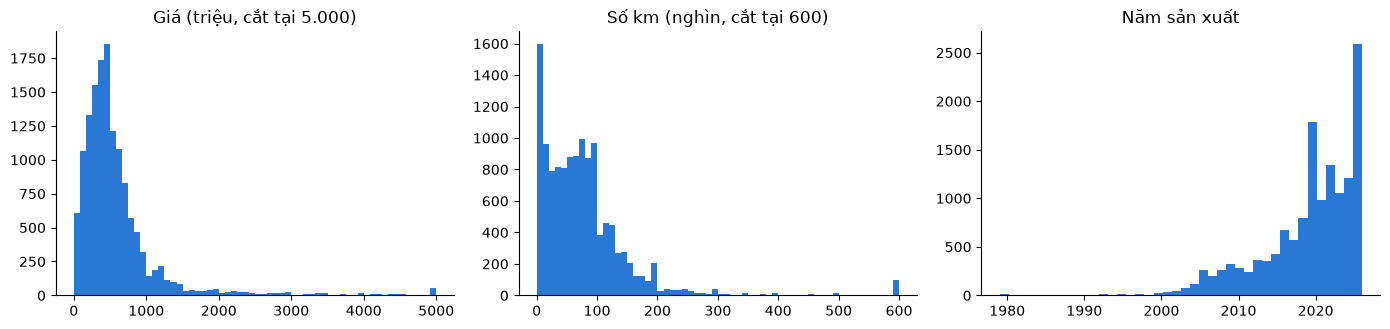

       price_tr  mileage_km   mfdate
count   14143.0     12665.0  14144.0
mean      600.0     81495.4   2019.0
std       737.9     96838.3      6.2
min         0.4         1.0   1979.0
0.1%        6.0         1.0   1984.0
1%         34.7         7.0   2001.0
50%       450.0     67000.0   2021.0
99%      3629.0    498484.5   2026.0
99.9%    7391.9   1000000.0   2026.0
max     40000.0   1000000.0   2026.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].hist(df["price_tr"].dropna().clip(upper=5000), bins=60, color=BLUE)
axes[0].set_title("Giá (triệu, cắt tại 5.000)")
axes[1].hist(df["mileage_km"].dropna().clip(upper=600000) / 1e3, bins=60, color=BLUE)
axes[1].set_title("Số km (nghìn, cắt tại 600)")
axes[2].hist(df["mfdate"].dropna(), bins=40, color=BLUE)
axes[2].set_title("Năm sản xuất")
fig.tight_layout()
plt.show()

print(df[["price_tr", "mileage_km", "mfdate"]].describe(percentiles=[.001, .01, .5, .99, .999]).round(1))

**Quy tắc (dựa trên hiểu biết thực tế, không dùng cắt phần trăm máy móc):**

| Cột | Quy tắc | Lý do |
|---|---|---|
| `price_tr` | loại nếu < 20 triệu hoặc > 10.000 triệu | Xe ô tô dưới 20 triệu gần như không tồn tại (thường là gõ thiếu số 0, hoặc đăng giá đặt cọc); trên 10 tỷ là gõ thừa số 0 hoặc xe siêu hiếm không đại diện cho thị trường. Không thể biết giá đúng nên **loại** thay vì sửa. |
| `price_tr` | loại nếu chữ số của giá là dãy liên tiếp (`123.456.789`, `12.345.678`, `23.456.789`...) | Giá là ô gõ tự do; người bán gõ dãy số này khi không muốn công khai giá ("liên hệ"). Đây là **giá giả**, không phải giá xe. Các giá như `399.999.999` hay `888.888.888` thì **giữ**: đó là cách định giá tâm lý (gần 400 triệu) hoặc số đẹp, vẫn là giá thật. |
| `price_tr` | loại nếu < 30% giá trung vị của xe cùng hãng, dòng, năm sản xuất (nhóm ≥ 3 xe) | Giá thấp bất thường so với chính mẫu xe đó thường là **tiền trả trước / đặt cọc**, không phải giá xe (ví dụ VinFast VF3 2026 mới rao 28 triệu). Xem mục 5.1. **Quy tắc này học trung vị từ dữ liệu nên được áp dụng ở `process_data.ipynb`, sau khi chia tập.** |
| `condition_ad` | ghi "Mới" nhưng xe **hơn 3 năm tuổi** → đổi thành "Đã sử dụng", số km coi là thiếu | Xe tồn kho ở đại lý có thể "mới" dù đời 1-3 năm trước (ví dụ BMW đời 2023 chưa lăn bánh), nhưng một chiếc Hyundai Tucson đời 2011 rao "mới" giá 255 triệu là ghi sai tình trạng. Nếu giữ nhãn "Mới", bước 6 sẽ điền 0 km cho xe này, sai hoàn toàn. |
| `mileage_km` | xe đã dùng mà > 500.000 km → thiếu | Vượt xa mức xe dân dụng chạy được, nhiều khả năng nhập thừa số 0 (ví dụ 1.000.000) |
| `mileage_km` | xe đã dùng, tuổi ≥ 2 năm mà < 100 km → thiếu | Xe 5 năm tuổi không thể chạy 10 km: người đăng nhập theo đơn vị nghìn km (10 = 10.000 km) hoặc nhập bừa. Không biết chắc đơn vị nên coi là thiếu rồi điền theo đời xe, an toàn hơn tự nhân 1000. |
| `mileage_km` | xe đã dùng, > 100.000 km/năm (km chia tuổi, tối thiểu 1 năm) → thiếu | Xe đời 1 tuổi mà đi 480.000 km là bất khả thi (xe dịch vụ chạy nhiều cũng chỉ khoảng 80.000-100.000 km/năm) |
| `mfdate` | giữ nguyên | Dải 1979-2026 hợp lệ; xe đời 2026 là xe năm nay/mới |

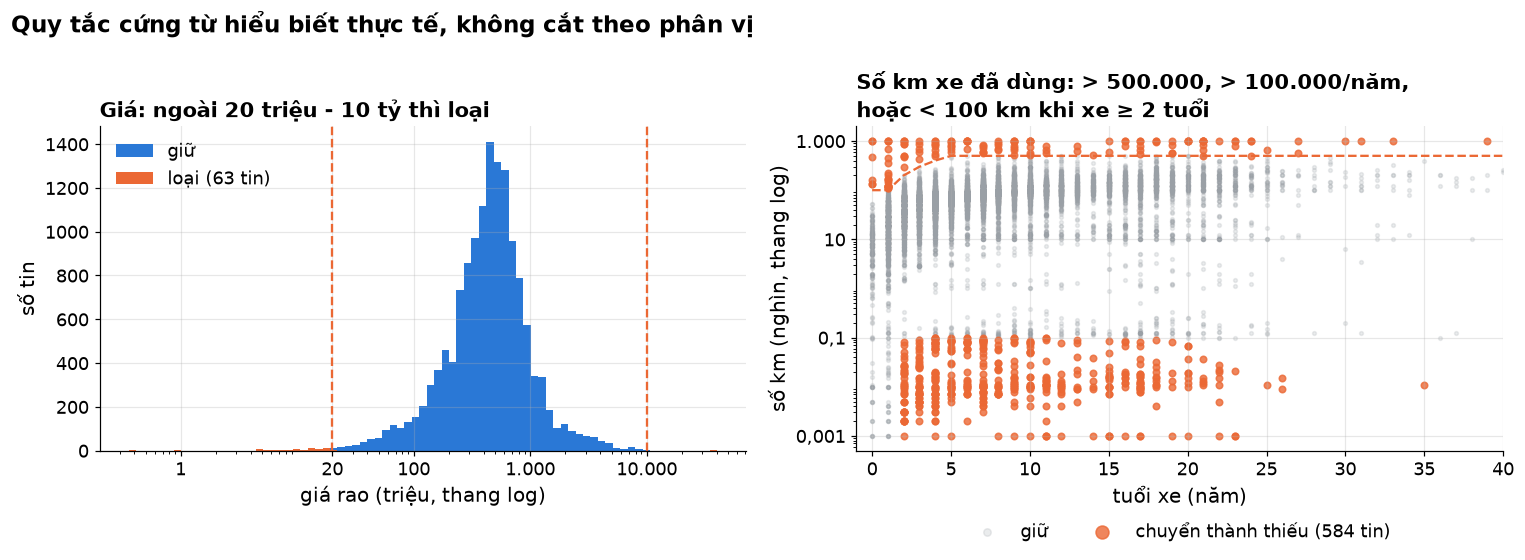

In [10]:
# Minh họa các quy tắc cứng (vẽ TRƯỚC khi áp dụng): giá và số km nằm ngoài vùng hợp lý
d = df[df["price_tr"].notna()]
bad_p = (d["price_tr"] < 20) | (d["price_tr"] > 10_000)
u = df[(df["condition_ad"] == "Đã sử dụng") & df["mileage_km"].notna()].copy()
u["age_"] = CURRENT_YEAR - u["mfdate"]
r_high = u["mileage_km"] > 500_000
r_low = (u["age_"] >= 2) & (u["mileage_km"] < 100)
r_rate = (u["mileage_km"] / u["age_"].clip(lower=1) > 100_000) & ~r_high
bad_k = r_high | r_low | r_rate
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
    bins = np.logspace(np.log10(d["price_tr"].min()), np.log10(d["price_tr"].max()), 80)
    axes[0].hist(d.loc[~bad_p, "price_tr"], bins=bins, color=BLUE, label="giữ")
    axes[0].hist(d.loc[bad_p, "price_tr"], bins=bins, color=ORANGE, label=f"loại ({vn(bad_p.sum())} tin)")
    for v in (20, 10_000):
        axes[0].axvline(v, color=ORANGE, ls="--", lw=1.5)
    axes[0].set_xscale("log"); axes[0].set_xticks([1, 20, 100, 1000, 10_000])
    axes[0].set_xticklabels(["1", "20", "100", "1.000", "10.000"])
    axes[0].set_xlabel("giá rao (triệu, thang log)"); axes[0].set_ylabel("số tin")
    axes[0].set_title("Giá: ngoài 20 triệu - 10 tỷ thì loại", fontsize=14); axes[0].legend(frameon=False)
    axes[1].scatter(u.loc[~bad_k, "age_"], u.loc[~bad_k, "mileage_km"].clip(1) / 1e3, s=6, alpha=0.2, color=GRAY,
                    label="giữ", rasterized=True)
    axes[1].scatter(u.loc[bad_k, "age_"], u.loc[bad_k, "mileage_km"].clip(1) / 1e3, s=18, alpha=0.8, color=ORANGE,
                    label=f"chuyển thành thiếu ({vn(bad_k.sum())} tin)")
    aa = np.arange(0, 45)
    axes[1].plot(aa, np.minimum(np.maximum(aa, 1) * 100, 500), color=ORANGE, ls="--", lw=1.5)
    axes[1].set_yscale("log"); axes[1].set_xlim(-1, 40)
    axes[1].set_yticks([0.001, 0.1, 10, 1000]); axes[1].set_yticklabels(["0,001", "0,1", "10", "1.000"])
    axes[1].set_xlabel("tuổi xe (năm)"); axes[1].set_ylabel("số km (nghìn, thang log)")
    axes[1].set_title("Số km xe đã dùng: > 500.000, > 100.000/năm,\nhoặc < 100 km khi xe ≥ 2 tuổi", fontsize=14)
    axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, markerscale=2)
    fig.suptitle("Quy tắc cứng từ hiểu biết thực tế, không cắt theo phân vị", x=0.01, ha="left", fontsize=15,
                 fontweight="bold")
    fig.tight_layout(); save(fig, "p10_gia_tri_bat_hop_ly"); save_slide(fig, "p10_gia_tri_bat_hop_ly"); plt.show()

In [11]:
n0 = len(df)

# Biến mục tiêu: bỏ dòng thiếu giá + giá bất hợp lý
bad_price = df["price_tr"].isna() | (df["price_tr"] < 20) | (df["price_tr"] > 10_000)
print(f"Loại {bad_price.sum()} dòng giá thiếu/bất hợp lý ({df['price_tr'].isna().sum()} thiếu, "
      f"{(df['price_tr'] < 20).sum()} < 20 triệu, {(df['price_tr'] > 10_000).sum()} > 10.000 triệu)")
df = df[~bad_price].reset_index(drop=True)
FUNNEL.append(("Loại giá thiếu, < 20 triệu, > 10 tỷ", len(df)))

# Giá giả: chữ số là dãy tăng liên tiếp (123456789, 12345678, 23456789, 1234567890...)
digits = df["price"].astype("int64").astype(str)
fake_price = digits.map(lambda s: len(s) >= 7 and s in "1234567890")
print(f"Loại {fake_price.sum()} tin có giá giả dạng dãy số liên tiếp:", sorted(digits[fake_price].unique()))
df = df[~fake_price].reset_index(drop=True)
FUNNEL.append(("Loại giá giả 123.456.789", len(df)))

df["age"] = CURRENT_YEAR - df["mfdate"]

# Tình trạng: "Mới" nhưng hơn 3 năm tuổi là ghi sai -> "Đã sử dụng" (số km đang trống, sẽ được điền ở mục 6)
wrong_new = (df["condition_ad"] == "Mới") & (df["age"] > 3)
print(f"\nXe ghi 'Mới' nhưng hơn 3 năm tuổi: {wrong_new.sum()} -> đổi thành 'Đã sử dụng'")
display(df.loc[wrong_new, ["carbrand", "carmodel", "mfdate", "condition_ad", "mileage_km", "price_tr"]])
df.loc[wrong_new, "condition_ad"] = "Đã sử dụng"

# Số km của xe đã dùng
used = df["condition_ad"] == "Đã sử dụng"
bad_km_high = used & (df["mileage_km"] > 500_000)
bad_km_low = used & (df["age"] >= 2) & (df["mileage_km"] < 100)
bad_km_rate = used & (df["mileage_km"] / df["age"].clip(lower=1) > 100_000) & ~bad_km_high
print(f"Số km bất hợp lý của xe đã dùng: {bad_km_high.sum()} quá cao, {bad_km_low.sum()} quá thấp, "
      f"{bad_km_rate.sum()} vượt 100.000 km/năm -> chuyển thành thiếu")
df.loc[bad_km_high | bad_km_low | bad_km_rate, "mileage_km"] = np.nan

print("Còn lại:", df.shape, f"(mất {n0 - len(df)} dòng)")

Loại 64 dòng giá thiếu/bất hợp lý (1 thiếu, 62 < 20 triệu, 1 > 10.000 triệu)
Loại 14 tin có giá giả dạng dãy số liên tiếp: ['123456789', '1234567890', '23456789', '234567890']

Xe ghi 'Mới' nhưng hơn 3 năm tuổi: 6 -> đổi thành 'Đã sử dụng'


,carbrand,carmodel,mfdate,condition_ad,mileage_km,price_tr
709,Kia,Carnival,2019,Mới,NaN,535.0
3197,Changan,Dòng khác,2018,Mới,NaN,105.0
5436,Hãng khác,Dòng khác,2020,Mới,NaN,110.0
9229,Hyundai,Tucson,2011,Mới,NaN,255.0
11749,Nissan,X Trail,2018,Mới,NaN,550.0
13277,Hyundai,Grand i10,2021,Mới,NaN,290.0


Số km bất hợp lý của xe đã dùng: 106 quá cao, 447 quá thấp, 25 vượt 100.000 km/năm -> chuyển thành thiếu
Còn lại: (14066, 14) (mất 78 dòng)


### 5.1 Giá trả trước / đặt cọc (nhãn sai)
Ngưỡng 20 triệu ở trên chỉ bắt được lỗi gõ thiếu số. Vẫn còn nhiều tin mà "giá" thực ra là **số tiền trả trước hoặc đặt cọc** (người bán ghi khoản trả trước cho dễ thu hút, phần còn lại trả góp), ví dụ xe đời 2025-2026 còn mới mà giá chỉ 30-100 triệu. Một con số tuyệt đối không bắt được trường hợp này vì 100 triệu là hợp lý với xe 20 năm tuổi nhưng vô lý với xe 1 năm tuổi.

> **Quy tắc này được áp dụng ở `process_data.ipynb` sau khi chia tập, dùng bảng trung vị học từ train**, không làm ở đây: trung vị giá của nhóm là một tham số học từ biến mục tiêu, nếu tính trên toàn bộ dữ liệu thì giá của tập test góp phần quyết định xóa dòng nào khỏi chính tập test.

**Quy tắc:** so với chính mẫu xe đó. Loại tin có giá **thấp hơn 30% giá trung vị của các xe cùng hãng, dòng và năm sản xuất**, chỉ xét nhóm có ít nhất 3 xe để trung vị đủ tin cậy. Không xe nào mất giá 70% so với xe cùng đời chỉ vì tình trạng hay số km.

**Vì sao quan trọng:** đây là **nhãn sai** nằm đúng ở biến cần dự đoán. Mô hình dự đoán đúng giá xe nhưng bị chấm là sai hàng trăm phần trăm, và phần lớn rơi vào phân khúc `< 200 triệu`, làm sai số của phân khúc này cao giả tạo.

> **Ghi chú:** đây là bước **sửa lỗi nhãn** (loại dòng có đáp án sai), không phải tạo đặc trưng: không có thông tin nào từ giá được đưa vào đầu vào của mô hình. Cách chặt chẽ hơn nữa là crawl thêm phần mô tả tin đăng và lọc theo từ khóa "trả trước", "góp", "cọc".

In [12]:
# Kiểm tra IQR trên log(giá) chỉ để THAM KHẢO: ngoại lệ thống kê, không xóa
lp = np.log(df["price_tr"])
q1, q3 = lp.quantile([.25, .75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
out = (lp < lo) | (lp > hi)
print(f"Ngoại lệ theo IQR(log giá): {out.sum()} dòng ({out.mean():.1%}), khoảng hợp lệ {np.exp(lo):.0f}-{np.exp(hi):.0f} triệu")
df.loc[out, ["carbrand", "carmodel", "mfdate", "price_tr"]].sort_values("price_tr", ascending=False).head(5)

Ngoại lệ theo IQR(log giá): 741 dòng (5.3%), khoảng hợp lệ 74-2574 triệu


,carbrand,carmodel,mfdate,price_tr
12976,Mercedes Benz,E Class,2023,9769.0
12138,Lexus,LX 600,2026,9700.0
7956,Bentley,Flying Spur,2021,9000.0
3248,Lexus,LX,2024,9000.0
13740,LandRover,Range Rover,2022,8900.0


Các ngoại lệ IQR còn lại chủ yếu là xe sang thật (Mercedes, BMW, Lexus, Porsche...) hoặc xe cổ rất rẻ. Đây là thông tin thật của thị trường nên **giữ nguyên**; ảnh hưởng của chúng lên mô hình được giảm bằng log-transform ở mục 8.1.

## 6. Điền giá trị thiếu bằng hằng số

Ở notebook này chỉ điền những giá trị **không học từ dữ liệu**:

| Cột | Điền | Vì sao làm được ở đây |
|---|---|---|
| `mileage_km` của **xe mới** | 0 km | quy tắc nghiệp vụ: trang xe mới không có ô số km, xe mới chưa chạy (thiếu có cấu trúc) |
| `carorigin` | nhãn `"Không rõ"` | hằng số; thiếu ~40% và không suy được từ dòng xe |

Các cột còn lại **cố ý để trống** và được điền ở `process_data.ipynb` bằng `CarImputer` (file `car_transformers.py`), với thống kê học **chỉ từ train**:

| Cột | Cách điền ở `process_data.ipynb` |
|---|---|
| `mileage_km` của xe đã dùng | trung vị số km của xe cùng đời (học từ train) + cột cờ `mileage_missing` |
| `cartype` | mode theo hãng + dòng xe (học từ train); không suy được → `"Không rõ"` |
| `carseats` | mode theo dòng xe → theo hãng → toàn cục (học từ train) |

**Cột đánh dấu `mileage_missing`** (tạo ở `process_data.ipynb`): giá trị điền là "đoán trung bình", không phải số đo thật. Cột này (1 = km gốc thiếu hoặc không tin được, đã điền; 0 = km do người bán khai) cho mô hình **biết** dòng nào là ước lượng. Xe mới không đánh dấu vì 0 km là giá trị đúng.

In [13]:
used = df["condition_ad"] == "Đã sử dụng"

# (a) xe mới: 0 km (thiếu có cấu trúc, quy tắc nghiệp vụ)
new_fill = ~used & df["mileage_km"].isna()
df.loc[new_fill, "mileage_km"] = 0
print(f"mileage_km: điền 0 km cho {new_fill.sum()} xe mới")

# (b) xuất xứ: nhãn hằng
n_origin = df["carorigin"].isna().sum()
df["carorigin"] = df["carorigin"].fillna("Không rõ")
print(f"carorigin: {n_origin} tin -> 'Không rõ'")

left = df[["mileage_km", "cartype", "carseats"]].isna().sum().to_frame("còn thiếu (điền ở process_data)")
left["%"] = (left.iloc[:, 0] / len(df) * 100).round(1)
left

mileage_km: điền 0 km cho 1226 xe mới
carorigin: 5831 tin -> 'Không rõ'


,còn thiếu (điền ở process_data),%
mileage_km,826,5.9
cartype,4623,32.9
carseats,3552,25.3


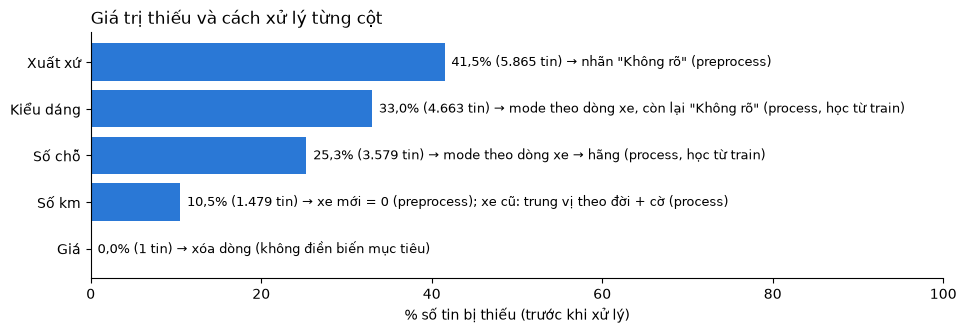

,cột,số thiếu,%,cách xử lý,nơi xử lý
0,Xuất xứ,5865,41.5,"nhãn ""Không rõ"" (preprocess)",preprocess_data
1,Kiểu dáng,4663,33.0,"mode theo dòng xe, còn lại ""Không rõ"" (process...",process_data
2,Số chỗ,3579,25.3,"mode theo dòng xe → hãng (process, học từ train)",process_data
3,Số km,1479,10.5,xe mới = 0 (preprocess); xe cũ: trung vị theo ...,preprocess_data (xe mới) + process_data (xe cũ)
4,Giá,1,0.0,xóa dòng (không điền biến mục tiêu),preprocess_data


In [14]:
# Tóm tắt: tỉ lệ thiếu của từng cột (phân tích ở mục 4), cách xử lý và nơi xử lý
COL_VI = {"carorigin": "Xuất xứ", "cartype": "Kiểu dáng", "carseats": "Số chỗ", "mileage_km": "Số km", "price_tr": "Giá"}
METHOD = {"carorigin": 'nhãn "Không rõ" (preprocess)',
          "cartype": 'mode theo dòng xe, còn lại "Không rõ" (process, học từ train)',
          "carseats": "mode theo dòng xe → hãng (process, học từ train)",
          "mileage_km": "xe mới = 0 (preprocess); xe cũ: trung vị theo đời + cờ (process)",
          "price_tr": "xóa dòng (không điền biến mục tiêu)"}
WHERE = {"carorigin": "preprocess_data", "cartype": "process_data", "carseats": "process_data",
         "mileage_km": "preprocess_data (xe mới) + process_data (xe cũ)", "price_tr": "preprocess_data"}
mb = miss_before.loc[[c for c in COL_VI if c in miss_before.index and miss_before.loc[c, "thiếu"] > 0]]
mb = mb.sort_values("%")

fig, ax = plt.subplots(figsize=(11, 3.2))
y = np.arange(len(mb))
ax.barh(y, mb["%"], color=BLUE)
for i, (c, r) in enumerate(mb.iterrows()):
    ax.text(r["%"] + 0.8, i, f"{vn(r['%'], 1)}% ({vn(r['thiếu'])} tin) → {METHOD[c]}", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([COL_VI[c] for c in mb.index])
ax.set_xlim(0, 100); ax.set_xlabel("% số tin bị thiếu (trước khi xử lý)")
ax.set_title("Giá trị thiếu và cách xử lý từng cột", loc="left"); ax.grid(axis="y", visible=False)
save(fig, "p02_thieu_va_cach_xu_ly"); plt.show()

# Bản cho slide: chữ to, chỉ ghi cách xử lý ngắn
SHORT_METHOD = {"carorigin": '"Không rõ"', "cartype": "mode theo dòng xe", "carseats": "mode dòng xe → hãng",
                "mileage_km": "mới = 0; cũ: trung vị đời xe", "price_tr": "xóa dòng"}
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.barh(y, mb["%"], color=BLUE, height=0.6)
    for i, (c, r) in enumerate(mb.iterrows()):
        ax.text(r["%"] + 1, i, f"{vn(r['%'], 1)}% → {SHORT_METHOD[c]}", va="center", fontsize=13)
    ax.set_yticks(y); ax.set_yticklabels([COL_VI[c] for c in mb.index])
    ax.set_xlim(0, 85); ax.set_xlabel("% số tin bị thiếu")
    ax.set_title("Bốn cột không bắt buộc thiếu nhiều; mỗi cột xử lý theo nguyên nhân thiếu")
    ax.grid(axis="y", visible=False)
    save_slide(fig, "p02_thieu_va_cach_xu_ly"); plt.close(fig)

gia_tri_thieu = pd.DataFrame({"cột": [COL_VI[c] for c in mb.index[::-1]],
                              "số thiếu": mb["thiếu"].values[::-1].astype(int),
                              "%": mb["%"].values[::-1],
                              "cách xử lý": [METHOD[c] for c in mb.index[::-1]],
                              "nơi xử lý": [WHERE[c] for c in mb.index[::-1]]})
save_table(gia_tri_thieu, "gia_tri_thieu", "Giá trị thiếu và cách xử lý", part="preprocess", index=False, floatfmt=".1f",
           note="Tính sau khi xóa tin trùng, trước khi điền.")
gia_tri_thieu

**Vì sao `cartype` không lùi về cấp hãng còn `carseats` thì có?** Trong cùng một dòng xe, kiểu dáng gần như cố định, nên điền theo dòng xe rất đáng tin. Nhưng một hãng bán đủ loại: Ford có cả Ranger (bán tải), Everest (SUV), Focus (sedan). Lấy kiểu dáng phổ biến nhất của hãng gán cho một xe "Dòng khác" là đoán mò, nên những xe này được ghi **"Không rõ"**. Số chỗ thì khác: đa số xe 5 chỗ, đoán sai theo hãng thường chỉ lệch 5 ↔ 7 chỗ và mô hình vẫn có hãng, dòng xe để bù lại.

> **Vì sao không điền ở đây?** Trung vị và mode là **tham số học từ dữ liệu**. Nếu tính trên toàn bộ dữ liệu rồi mới chia train/test, các xe trong tập test góp phần tạo ra giá trị điền, và điểm đánh giá trên test không còn là ước lượng cho dữ liệu hoàn toàn mới (rò rỉ dữ liệu). Vì vậy `process_data.ipynb` chia tập trước, học trung vị / mode **chỉ từ train**, rồi áp cùng các giá trị đó lên test.

## 7. EDA: phân tích khám phá

Mục này mô tả quan hệ giữa giá và các đặc trưng, để định hướng bước xử lý và chọn mô hình.

**EDA được phép dùng toàn bộ dữ liệu đã làm sạch** vì nó chỉ để mô tả và định hướng, **không sinh ra tham số nào đi vào mô hình** (không có trung vị, ngưỡng hay bảng tra nào từ đây được dùng ở bước sau). Lưu ý dữ liệu ở bước này còn chứa các tin giá trả trước / đặt cọc (lọc ở `process_data.ipynb`), nên một số điểm giá thấp bất thường vẫn xuất hiện.

Mỗi hình được lưu hai bản: `figures/p05-p09_*.png` cho báo cáo và `figures/slides/s01-s05_*` (PNG + PDF) cho slide.

14066 tin; giá trung vị: xe 0 tuổi 624 triệu, 5 tuổi 498, 10 tuổi 335, 15 tuổi 205


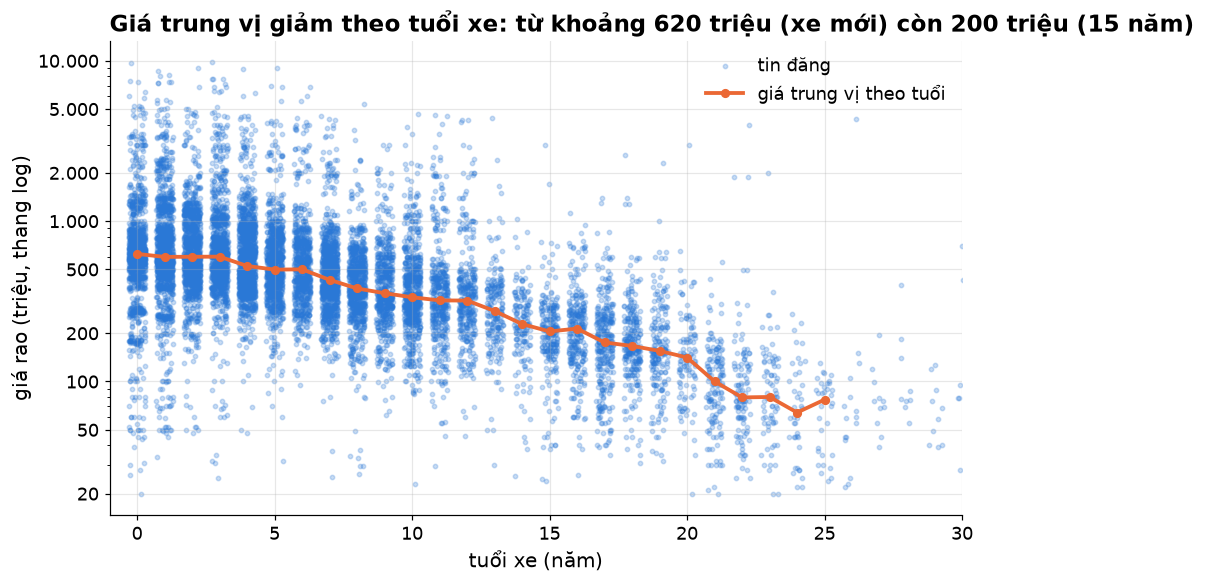

In [15]:
# 7.1 Giá theo tuổi xe
d = df[["age", "price_tr"]].dropna()
med_age = d.groupby("age")["price_tr"].agg(["median", "size"])
med_age = med_age[med_age["size"] >= 20]
print(f"{len(d)} tin; giá trung vị: xe 0 tuổi {vn(med_age.loc[0, 'median'])} triệu, "
      f"5 tuổi {vn(med_age.loc[5, 'median'])}, 10 tuổi {vn(med_age.loc[10, 'median'])}, 15 tuổi {vn(med_age.loc[15, 'median'])}")

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots()
    jitter = np.random.RandomState(RANDOM_STATE).uniform(-0.3, 0.3, len(d))
    ax.scatter(d["age"] + jitter, d["price_tr"], s=8, alpha=0.25, color=BLUE, label="tin đăng", rasterized=True)
    ax.plot(med_age.index, med_age["median"], color=ORANGE, lw=2.5, marker="o", ms=5, label="giá trung vị theo tuổi")
    ax.set_yscale("log"); ax.set_xlim(-1, 30)
    ax.set_yticks([20, 50, 100, 200, 500, 1000, 2000, 5000, 10000])
    ax.set_yticklabels(["20", "50", "100", "200", "500", "1.000", "2.000", "5.000", "10.000"])
    ax.set_xlabel("tuổi xe (năm)"); ax.set_ylabel("giá rao (triệu, thang log)")
    ax.set_title("Giá trung vị giảm theo tuổi xe: từ khoảng 620 triệu (xe mới) còn 200 triệu (15 năm)")
    ax.legend(frameon=False, loc="upper right")
    save(fig, "p05_eda_gia_theo_tuoi"); save_slide(fig, "s01_eda_gia_theo_tuoi"); plt.show()

**Nhận xét:** giá trung vị gần như đứng yên trong 3 năm đầu (khoảng 600-620 triệu, vì nhóm xe 0-3 tuổi gồm cả xe mới giá rẻ như VinFast VF3 lẫn xe đời mới giá cao), sau đó giảm khá đều: 498 triệu ở 5 năm, 335 triệu ở 10 năm, 205 triệu ở 15 năm, rồi giảm nhanh hơn sau 20 năm. Trên thang log, một đường giảm đều nghĩa là xe mất giá theo **tỉ lệ %** gần như không đổi mỗi năm, nên học trên **log(giá)** (mục 8) là hợp lý. Đường không hoàn toàn thẳng (phẳng ở đầu, dốc ở cuối), nên Ridge cần thêm `age²`, còn Random Forest tự học được bằng các ngưỡng chia. Cùng một tuổi, giá trải rộng gấp hàng chục lần: tuổi xe quan trọng nhưng không đủ, cần thêm hãng và dòng xe.

carbrand   Lexus     BMW  Mercedes Benz    Ford  VinFast  Mazda  Honda     Kia  Mitsubishi  Toyota  Hyundai  Nissan     MG  Suzuki  Chevrolet
median    1820.0  1000.0          900.0   599.0    510.0  500.0  479.0   445.0       425.0   409.0    399.0   370.0  360.0   355.0      145.0
size       159.0   278.0          783.0  1594.0   1257.0  751.0  580.0  1339.0      1045.0  2843.0   1228.0   152.0  179.0   321.0      409.0


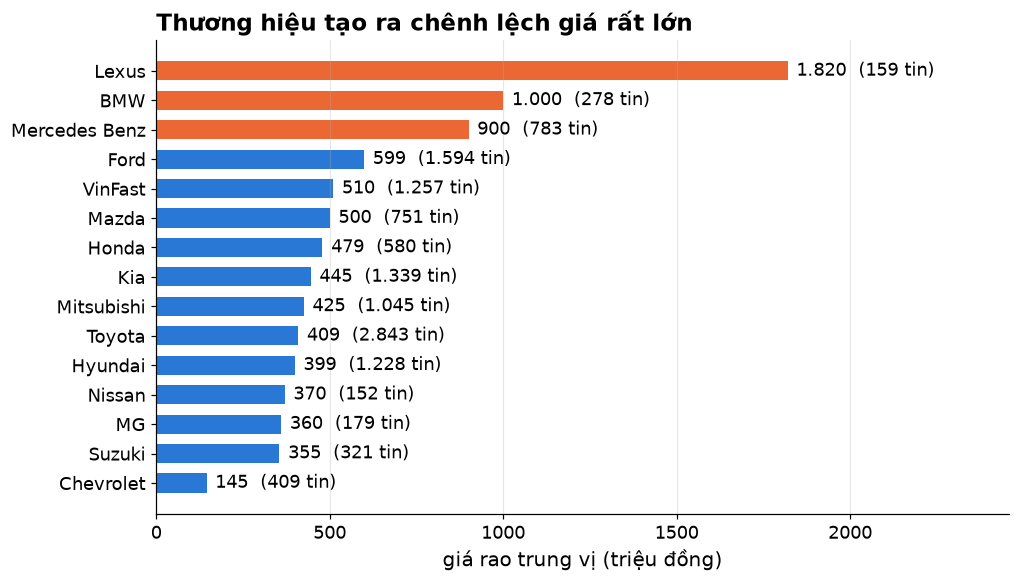

In [16]:
# 7.2 Giá trung vị theo hãng (15 hãng nhiều tin nhất)
top = df["carbrand"].value_counts().head(15).index
bstat = (df[df["carbrand"].isin(top)].groupby("carbrand")["price_tr"]
         .agg(["median", "size"]).sort_values("median"))
print(bstat.sort_values("median", ascending=False).round(0).T)

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots()
    lux = bstat.index.isin({"Lexus", "BMW", "Mercedes Benz", "Porsche", "LandRover", "Audi", "Volvo"})
    ax.barh(bstat.index, bstat["median"], color=np.where(lux, ORANGE, BLUE), height=0.65)
    for i, (b, r) in enumerate(bstat.iterrows()):
        ax.text(r["median"] + 25, i, f"{vn(r['median'])}  ({vn(r['size'])} tin)", va="center", fontsize=12)
    ax.set_xlim(0, bstat["median"].max() * 1.35)
    ax.set_xlabel("giá rao trung vị (triệu đồng)")
    ax.set_title("Thương hiệu tạo ra chênh lệch giá rất lớn")
    ax.grid(axis="y", visible=False)
    save(fig, "p06_eda_gia_theo_hang"); save_slide(fig, "s02_eda_gia_theo_hang"); plt.show()

**Nhận xét:** trong 15 hãng nhiều tin nhất, ba hãng sang (màu cam: Lexus 1.820 triệu, BMW 1.000 triệu, Mercedes 900 triệu) có giá trung vị gấp 2-4 lần nhóm phổ thông (Toyota 409, Hyundai 399, Kia 445) và gấp hơn 10 lần Chevrolet (145, phần lớn xe đời cũ). Hãng là thông tin mà tuổi xe không thay thế được, nên phải giữ làm đặc trưng. Ngoài 15 hãng này còn hàng chục hãng ít tin; đó là lý do cần **gộp nhãn hiếm theo cấp** (dòng xe → hãng → nhóm hãng cao cấp / phổ thông) ở `process_data.ipynb`, thay vì dồn mọi hãng hiếm vào một nhãn chung.

Bỏ 826 xe đã dùng thiếu số km (sẽ được điền ở process_data); vẽ 12014 xe
giá trung vị theo nhóm km (nghìn km): {10.0: 518.0, 30.0: 580.0, 50.0: 555.0, 70.0: 476.0, 90.0: 395.0, 110.0: 350.0, 130.0: 295.0, 150.0: 280.0, 170.0: 240.0, 190.0: 195.0, 210.0: 249.0, 230.0: 245.0, 250.0: 130.0, 270.0: 254.0, 290.0: 158.0}


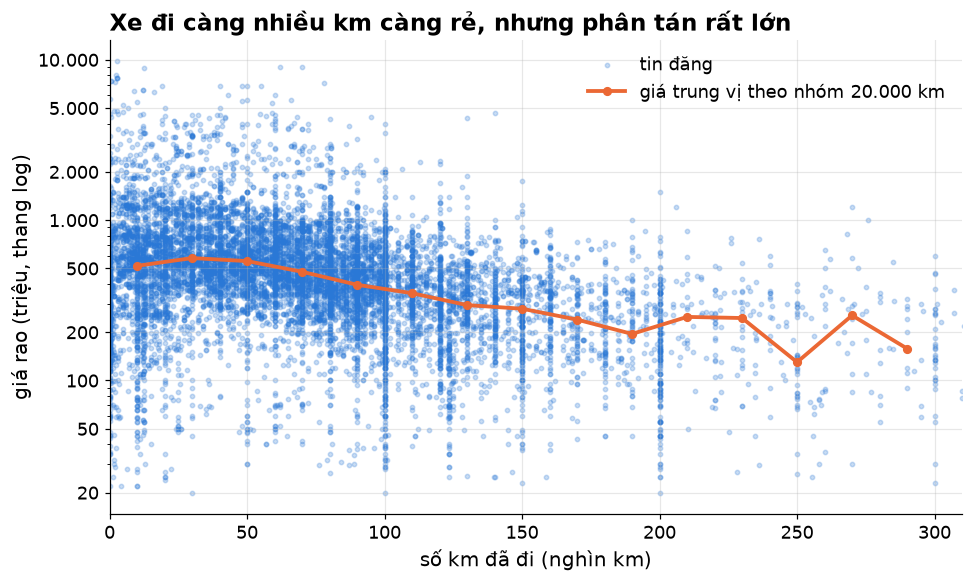

In [17]:
# 7.3 Giá theo số km (chỉ xe đã dùng có số km; xe mới = 0 km không đưa vào)
used_km = df[(df["condition_ad"] == "Đã sử dụng")][["mileage_km", "price_tr"]]
d = used_km.dropna()
print(f"Bỏ {used_km['mileage_km'].isna().sum()} xe đã dùng thiếu số km (sẽ được điền ở process_data); vẽ {len(d)} xe")
bins = np.arange(0, 320_000, 20_000)
d_b = d.assign(bin=pd.cut(d["mileage_km"], bins, labels=(bins[:-1] + 10_000) / 1e3))
med_km = d_b.groupby("bin", observed=True)["price_tr"].agg(["median", "size"])
med_km = med_km[med_km["size"] >= 30]
print("giá trung vị theo nhóm km (nghìn km):", med_km["median"].round(0).to_dict())

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots()
    ax.scatter(d["mileage_km"] / 1e3, d["price_tr"], s=8, alpha=0.25, color=BLUE, label="tin đăng", rasterized=True)
    ax.plot(med_km.index.astype(float), med_km["median"], color=ORANGE, lw=2.5, marker="o", ms=5,
            label="giá trung vị theo nhóm 20.000 km")
    ax.set_yscale("log"); ax.set_xlim(0, 310)
    ax.set_yticks([20, 50, 100, 200, 500, 1000, 2000, 5000, 10000])
    ax.set_yticklabels(["20", "50", "100", "200", "500", "1.000", "2.000", "5.000", "10.000"])
    ax.set_xlabel("số km đã đi (nghìn km)"); ax.set_ylabel("giá rao (triệu, thang log)")
    ax.set_title("Xe đi càng nhiều km càng rẻ, nhưng phân tán rất lớn")
    ax.legend(frameon=False, loc="upper right")
    save(fig, "p07_eda_gia_theo_km"); save_slide(fig, "s03_eda_gia_theo_km"); plt.show()

**Nhận xét:** giá trung vị nhìn chung giảm khi số km tăng (khoảng 520-580 triệu ở dưới 40.000 km, 395 triệu ở 90.000 km, 280 triệu ở 150.000 km), nhưng độ phân tán ở mỗi mức km rất lớn, vì số km đi cùng với tuổi xe (xe càng cũ càng đi nhiều). Số km mang một phần thông tin trùng với tuổi xe; phần riêng của nó là **mức độ sử dụng**, nên tạo thêm `km_per_year` (km / tuổi) ở `process_data.ipynb` để tách hai thông tin này. Phân phối số km lệch phải mạnh, nên Ridge dùng `log(km)`.

Số cặp đủ dữ liệu ít nhất: 9983
          Tuổi xe  Số km  Số chỗ  log(giá)
Tuổi xe      1.00   0.54    0.00     -0.60
Số km        0.54   1.00    0.16     -0.38
Số chỗ       0.00   0.16    1.00      0.09
log(giá)    -0.60  -0.38    0.09      1.00


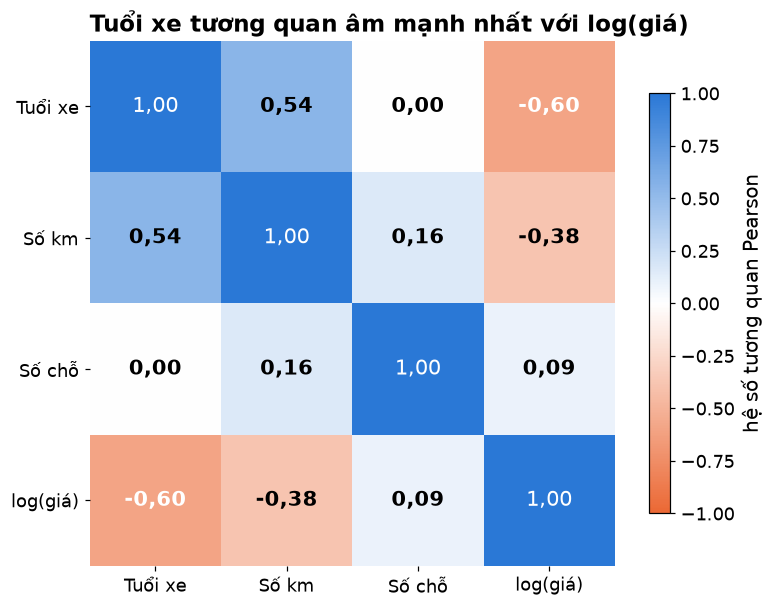

In [18]:
# 7.4 Tương quan giữa các biến số (bỏ km_per_year vì chưa tạo ở bước này)
NUM_EDA = {"age": "Tuổi xe", "mileage_km": "Số km", "carseats": "Số chỗ", "price_log": "log(giá)"}
tmp = df.assign(price_log=np.log(df["price_tr"]))[list(NUM_EDA)].rename(columns=NUM_EDA)
corr = tmp.corr(method="pearson")          # tương quan theo cặp, bỏ dòng thiếu của từng cặp
print("Số cặp đủ dữ liệu ít nhất:", int(tmp.notna().astype(int).T.dot(tmp.notna().astype(int)).values.min()))
print(corr.round(2))

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("cam_xanh", [ORANGE, "#ffffff", BLUE])
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(8, 6.2))
    im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
    for i in range(len(corr)):
        for j in range(len(corr)):
            v = corr.values[i, j]
            ax.text(j, i, vn(v, 2), ha="center", va="center", fontsize=14,
                    color="white" if abs(v) > 0.6 else "black", fontweight="bold" if i != j else "normal")
    ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns)
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("hệ số tương quan Pearson")
    ax.set_title("Tuổi xe tương quan âm mạnh nhất với log(giá)")
    save(fig, "p08_eda_tuong_quan"); save_slide(fig, "s04_eda_tuong_quan"); plt.show()

**Nhận xét:** tuổi xe có tương quan âm mạnh nhất với log(giá) (−0,60); số km cũng tương quan âm với giá (−0,38) nhưng tương quan dương khá mạnh với tuổi xe (0,54), tức hai biến **mang trùng một phần thông tin**. Đây là lý do khi đọc độ quan trọng đặc trưng ở `model.ipynb` phải kiểm tra thêm bằng permutation importance (impurity bị lệch khi đặc trưng tương quan). Số chỗ gần như không tương quan tuyến tính với giá, nhưng có thể vẫn có ích qua tương tác với kiểu dáng; tương quan Pearson chỉ đo quan hệ tuyến tính giữa các biến số.

C:\Users\G3 15\AppData\Local\Temp\ipykernel_12096\4687032.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.6,
C:\Users\G3 15\AppData\Local\Temp\ipykernel_12096\4687032.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.6,


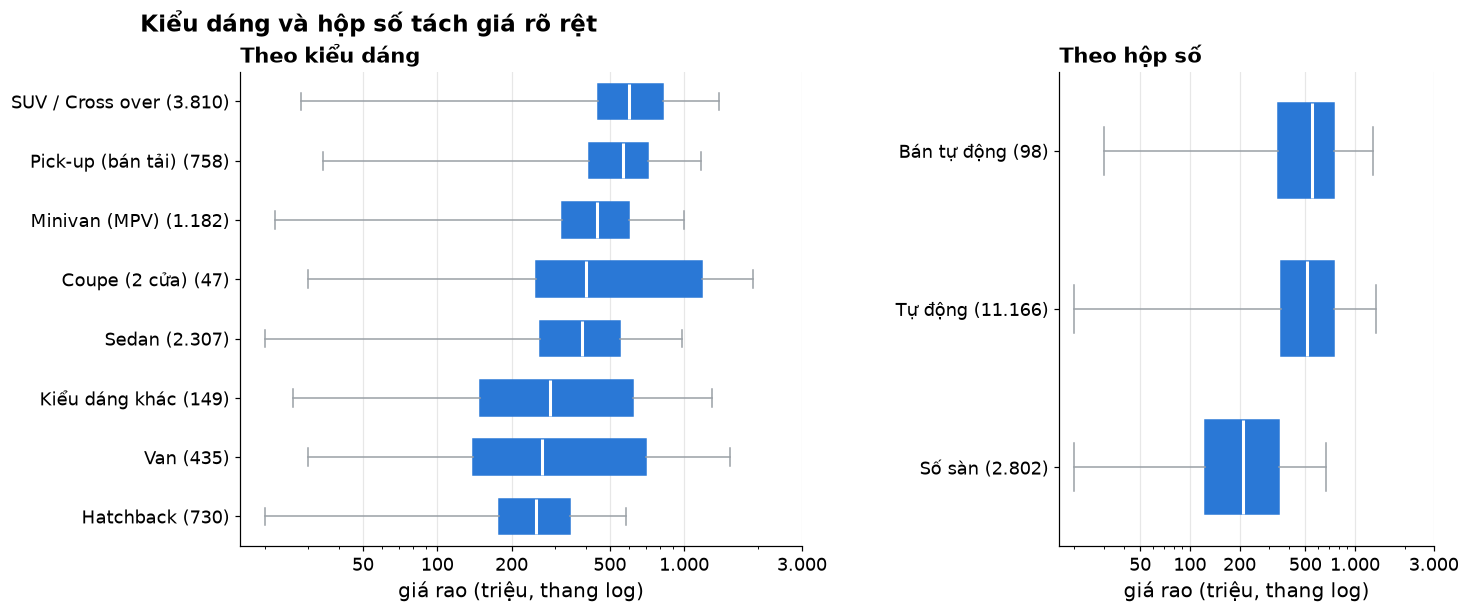

Giá trung vị theo kiểu dáng: {'Hatchback': 250.0, 'Van': 265.0, 'Kiểu dáng khác': 285.0, 'Sedan': 387.0, 'Coupe (2 cửa)': 400.0, 'Minivan (MPV)': 445.0, 'Pick-up (bán tải)': 565.0, 'SUV / Cross over': 600.0}
Giá trung vị theo hộp số: {'Số sàn': 210.0, 'Tự động': 515.0, 'Bán tự động': 552.0}


In [19]:
# 7.5 Phân phối giá theo kiểu dáng và hộp số (boxplot, ẩn điểm ngoại lai)
def boxes(ax, col, min_n=30):
    d = df[[col, "price_tr"]].dropna()
    counts = d[col].value_counts()
    keep_lab = counts[counts >= min_n].index
    order = d[d[col].isin(keep_lab)].groupby(col)["price_tr"].median().sort_values().index
    data = [d.loc[d[col] == k, "price_tr"] for k in order]
    bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color="white", lw=2))
    for b in bp["boxes"]:
        b.set(facecolor=BLUE, edgecolor=BLUE)
    for k in ("whiskers", "caps"):
        for x in bp[k]:
            x.set(color=GRAY)
    ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels([f"{k} ({vn(counts[k])})" for k in order])
    ax.set_xscale("log"); ax.set_xticks([50, 100, 200, 500, 1000, 3000])
    ax.set_xticklabels(["50", "100", "200", "500", "1.000", "3.000"])
    ax.set_xlabel("giá rao (triệu, thang log)"); ax.grid(axis="y", visible=False)
    return d.groupby(col)["price_tr"].median().reindex(order)


with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.55})
    m_type = boxes(axes[0], "cartype"); axes[0].set_title("Theo kiểu dáng", fontsize=14)
    m_gear = boxes(axes[1], "gearbox"); axes[1].set_title("Theo hộp số", fontsize=14)
    fig.suptitle("Kiểu dáng và hộp số tách giá rõ rệt", x=0.06, ha="left", fontsize=15, fontweight="bold")
    save(fig, "p09_eda_gia_theo_kieu_dang"); save_slide(fig, "s05_eda_gia_theo_kieu_dang"); plt.show()
print("Giá trung vị theo kiểu dáng:", m_type.round(0).to_dict())
print("Giá trung vị theo hộp số:", m_gear.round(0).to_dict())

**Nhận xét:** giá khác nhau rõ theo kiểu dáng (trung vị SUV 600 triệu, bán tải 565, MPV 445, Sedan 387, Hatchback 250) và theo hộp số (số sàn 210 triệu so với tự động 515, phần lớn vì xe số sàn là xe đời cũ). Kiểu dáng thiếu khoảng 1/3 nhưng mang thông tin giá rõ, nên **đáng điền theo dòng xe** thay vì bỏ cột. Hộp số trùng một phần thông tin với tuổi xe (giống số km), một lần nữa cho thấy cần permutation importance khi diễn giải mô hình. Ba cột phân loại này không có thứ tự tự nhiên nên được **mã hóa one-hot** ở `model.ipynb`.

## 8. Biến đổi, gộp nhãn hiếm và tạo đặc trưng

### 8.1 Biến đổi log cho giá
Giá lệch phải mạnh (đa số xe 200-800 triệu, vài xe vài tỷ). Phân phối lệch làm mô hình hồi quy bị kéo bởi vài điểm lớn và sai số lớn dồn vào xe đắt. `log(giá)` đưa phân phối về gần đối xứng và biến chênh lệch tuyệt đối thành chênh lệch **tương đối** (xe 100 triệu → 150 triệu và 1 tỷ → 1,5 tỷ đều là +50%), khớp với cách người mua nghĩ về giá. `log` là biến đổi tất định bằng công thức, không có tham số nào học từ dữ liệu, nên làm ở đây được.

Độ lệch (skewness): giá gốc = 5.07, log(giá) = -0.26


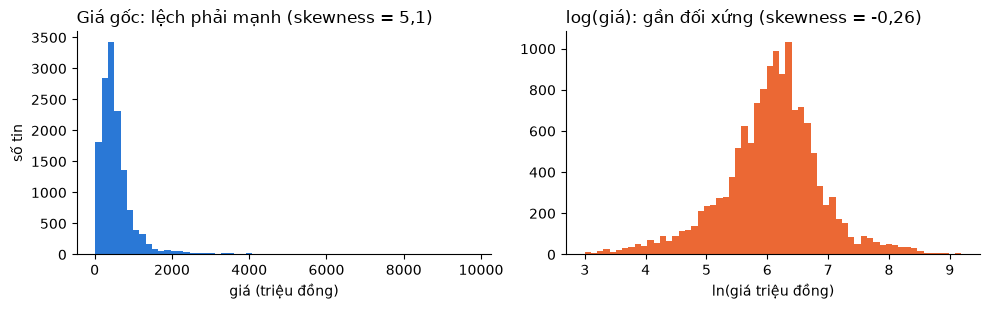

In [20]:
from scipy.stats import skew
df["price_log"] = np.log(df["price_tr"])
print(f"Độ lệch (skewness): giá gốc = {skew(df['price_tr']):.2f}, log(giá) = {skew(df['price_log']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df["price_tr"], bins=60, color=BLUE)
axes[0].set_title(f"Giá gốc: lệch phải mạnh (skewness = {skew(df['price_tr']):.1f})".replace(".", ","), loc="left")
axes[0].set_xlabel("giá (triệu đồng)"); axes[0].set_ylabel("số tin")
axes[1].hist(df["price_log"], bins=60, color=ORANGE)
axes[1].set_title(f"log(giá): gần đối xứng (skewness = {skew(df['price_log']):.2f})".replace(".", ","), loc="left")
axes[1].set_xlabel("ln(giá triệu đồng)")
fig.tight_layout()
save(fig, "p03_gia_va_log_gia"); plt.show()

# Bản cho slide (2 panel, chữ to)
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].hist(df["price_tr"].clip(upper=6000), bins=60, color=BLUE)
    axes[0].set_title(f"Giá gốc: lệch phải (skewness {vn(skew(df['price_tr']), 1)})", fontsize=14)
    axes[0].set_xlabel("giá (triệu đồng, cắt tại 6.000)"); axes[0].set_ylabel("số tin")
    axes[1].hist(df["price_log"], bins=60, color=ORANGE)
    axes[1].set_title(f"log(giá): gần đối xứng (skewness {vn(skew(df['price_log']), 2)})", fontsize=14)
    axes[1].set_xlabel("ln(giá triệu đồng)")
    for ax in axes:
        ax.grid(axis="x", visible=False)
    fig.suptitle("Học trên log(giá) để sai số tính theo phần trăm", x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout(); save_slide(fig, "p03_gia_va_log_gia"); plt.close(fig)

**Gắn với bài toán dự đoán giá:** `price_log` sẽ là **biến mục tiêu** mà mô hình học. Sau khi dự đoán chỉ cần `exp()` để đổi về triệu đồng. Lựa chọn này được kiểm chứng bằng số liệu ở `model.ipynb` (mục 9): so sánh huấn luyện Random Forest trên giá gốc và trên log giá bằng cross-validation **trên tập train**.

### 8.2 Gộp nhãn hiếm theo cấp: thực hiện ở `process_data.ipynb`
`carbrand` có ~70 hãng, `carmodel` hơn 500 tổ hợp hãng + dòng, nhiều nhãn chỉ có 1-5 tin, nên cần gộp nhãn hiếm theo cấp (dòng xe → hãng → nhóm hãng cao cấp / phổ thông, ngưỡng 30 / 10 tin).

Việc **đếm tần suất** để quyết định nhãn nào đủ ngưỡng là học tham số từ dữ liệu: một dòng xe có 9 tin ở train và 2 tin ở test sẽ được giữ nếu đếm trên toàn bộ, nhưng bị gộp nếu chỉ đếm trên train. Vì vậy bước này chuyển sang `process_data.ipynb` (`BrandModelGrouper`, fit trên train). Phần giải thích chi tiết và thí nghiệm chọn ngưỡng bằng cross-validation cũng chuyển sang đó. File xuất ở đây giữ nguyên cột gốc `carbrand`, `carmodel`.

### 8.3 Tạo đặc trưng
- `age` = 2026 − năm sản xuất (tạo ở mục 5). Tuổi xe có ý nghĩa trực tiếp hơn một con số năm tuyệt đối. Đây là công thức tất định nên làm ở đây.
- `km_per_year` = km / max(tuổi, 1) và `mileage_missing` **phụ thuộc giá trị số km đã điền**, nên tạo ở `process_data.ipynb` sau khi điền.
- `province` (tỉnh/thành dạng slug, tạo ở mục 3): giữ trong file để mô tả dữ liệu; thí nghiệm ở `process_data.ipynb` cho thấy vị trí gần như không giúp dự đoán.

**Biến đổi riêng cho từng mô hình:** `age²`, `log(km)`, `log(km/năm)` chỉ cần cho **mô hình tuyến tính** (Ridge), để quan hệ cong (xe mất giá nhanh những năm đầu rồi chậm lại) trở nên gần tuyến tính. **Mô hình cây** chỉ so sánh ngưỡng nên không bị ảnh hưởng bởi biến đổi đơn điệu: `age` và `age²` mang cùng một thông tin. Các cột này được tạo ở `process_data.ipynb`.

In [21]:
df["mfdate"] = df["mfdate"].astype(int)
df["age"] = df["age"].astype(int)
# carseats còn NaN (điền ở process_data) nên giữ kiểu số thực
df[["age", "mileage_km", "carseats"]].describe().round(1)

,age,mileage_km,carseats
count,14066.0,13240.0,10514.0
mean,7.0,69950.9,5.9
std,6.2,62945.4,1.8
min,0.0,0.0,2.0
25%,2.0,20000.0,5.0
50%,5.0,61000.0,5.0
75%,10.0,99999.0,7.0
max,47.0,500000.0,16.0


## 9. Xử lý dữ liệu mất cân bằng, chia train/test, mã hóa và chuẩn hóa

### 9.1 Mất cân bằng trong bài toán hồi quy nghĩa là gì?
Biến mục tiêu `price_tr` là số liên tục nên không có "lớp thiểu số" như bài toán phân loại. Mất cân bằng ở đây thể hiện ở **mật độ dữ liệu theo vùng giá**: phần lớn xe nằm ở phân khúc phổ thông (vài trăm triệu), còn xe sang vài tỷ rất ít. Mô hình tối ưu sai số trung bình sẽ học tốt vùng đông mẫu và **dự đoán kém ở vùng hiếm** (thường là đúng nhóm xe giá trị cao, nơi sai số tuyệt đối đắt nhất).

Để định lượng, chia giá thành các **phân khúc** (chỉ dùng để phân tích, chia mẫu và đánh giá, không làm đặc trưng):

,số mẫu,%,gấp (so với phân khúc lớn nhất)
segment,,,
< 200 triệu,2093,14.9,2.8
200-500,5915,42.1,1.0
500-1.000,4529,32.2,1.3
1-2 tỷ,1071,7.6,5.5
> 2 tỷ,458,3.3,12.9


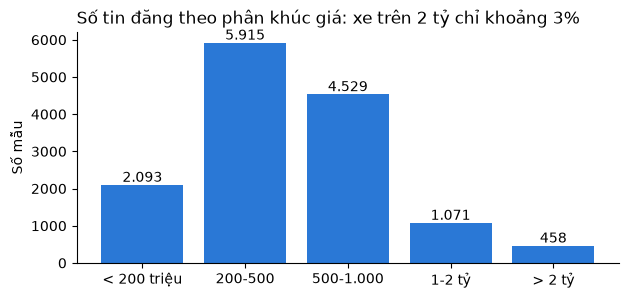

In [22]:
SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]
df["segment"] = pd.cut(df["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False)

seg = df["segment"].value_counts().reindex(SEG_LABELS)
tbl = pd.DataFrame({"số mẫu": seg, "%": (seg / len(df) * 100).round(1),
                    "gấp (so với phân khúc lớn nhất)": (seg.max() / seg).round(1)})
display(tbl)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(seg.index.astype(str), seg.values, color=BLUE)
for x, v in enumerate(seg.values):
    ax.text(x, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
ax.set_title("Số tin đăng theo phân khúc giá: xe trên 2 tỷ chỉ khoảng 3%", loc="left")
ax.set_ylabel("Số mẫu")
save(fig, "p04_phan_khuc_gia"); plt.show()
save_table(tbl.rename_axis("phân khúc"), "phan_khuc_gia", "Số tin theo phân khúc giá", part="preprocess", floatfmt=".1f",
           note="Tính trên dữ liệu sau tiền xử lý, trước khi lọc giá đặt cọc ở process_data.")

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = [ORANGE if s == "> 2 tỷ" else BLUE for s in SEG_LABELS]
    ax.bar(SEG_LABELS, seg.values, color=colors, width=0.65)
    for x, (v, pct) in enumerate(zip(seg.values, tbl["%"].values)):
        ax.text(x, v + 60, f"{vn(v)}\n({vn(pct, 1)}%)", ha="center", va="bottom", fontsize=13)
    ax.set_ylim(0, seg.max() * 1.25); ax.set_ylabel("số tin"); ax.set_xlabel("phân khúc giá")
    ax.set_title(f"Mất cân bằng: xe trên 2 tỷ chỉ chiếm {vn(tbl.loc['> 2 tỷ', '%'], 1)}% số tin")
    ax.grid(axis="x", visible=False)
    save_slide(fig, "p04_phan_khuc_gia"); plt.close(fig)

Phân khúc `> 2 tỷ` ít hơn phân khúc lớn nhất khoảng 10 lần trở lên → mất cân bằng thật sự. Ngoài ra các **đặc trưng** cũng lệch (xem bên dưới), đặc biệt `condition_ad` (xe mới chỉ ~9%), `fuel` (Hybrid ~2%) và `gearbox` (bán tự động <1%).

In [23]:
for col in ["fuel", "gearbox", "condition_ad"]:
    vc = df[col].value_counts()
    print(f"--- {col} ---")
    print(pd.DataFrame({"số mẫu": vc, "%": (vc / vc.sum() * 100).round(1)}), "\n")

--- fuel ---
                số mẫu     %
fuel                        
Xăng             10231  72.7
Dầu               2435  17.3
Điện              1092   7.8
Động cơ Hybrid     308   2.2 

--- gearbox ---
             số mẫu     %
gearbox                  
Tự động       11166  79.4
Số sàn         2802  19.9
Bán tự động      98   0.7 

--- condition_ad ---
              số mẫu     %
condition_ad              
Đã sử dụng     12840  91.3
Mới             1226   8.7 



### 9.2 Chia train/test (ở `process_data.ipynb`), mã hóa, chuẩn hóa (ở `model.ipynb`)
Các bước này học tham số từ dữ liệu hoặc phụ thuộc vào mô hình nên **không** làm ở notebook này. Nguyên tắc được dùng:

- **Chia 80/20, phân tầng theo phân khúc giá** (`random_state = 42`). Chia ngẫu nhiên thông thường có thể để tập test gần như không có xe > 2 tỷ, khiến điểm đánh giá nhìn đẹp nhưng không phản ánh khả năng với xe sang. Phân tầng đảm bảo mỗi phân khúc có cùng tỉ lệ ở cả hai tập. Tập test giữ nguyên phân phối thật, **không** cân bằng lại.
- **Không dùng tập validation riêng:** tham số được chọn bằng 5-fold cross-validation (hoặc OOB với Random Forest) **trên tập train**. Với khoảng 11 nghìn tin train và chỉ 366 xe trên 2 tỷ trong đó (458 trên toàn bộ dữ liệu), CV ổn định hơn một tập validation cố định. Tập test chỉ dùng **một lần** để báo cáo kết quả cuối.
- **Đặc trưng:** chỉ gồm thông tin người mua thấy trong tin đăng. Không đưa `price_tr`, `price_log` (đáp án) và `mfdate` (trùng `age`); `carbrand`/`carmodel` thay bằng bản đã gộp nhãn (`*_grp`).
- **One-hot** cho biến phân loại: hãng, dòng xe, nhiên liệu... không có thứ tự (Toyota không "lớn hơn" Ford); mã hóa 0, 1, 2... sẽ tạo thứ bậc giả. `handle_unknown="ignore"` để nhãn lạ ở test không gây lỗi.
- **StandardScaler** cho biến số: cần cho mô hình dựa trên gradient/khoảng cách (Ridge); mô hình cây không cần nhưng không bị hại.
- Bộ mã hóa/chuẩn hóa **fit chỉ trên train rồi áp lên test**, để thống kê của test không rò rỉ vào huấn luyện.

### 9.3 Kỹ thuật xử lý mất cân bằng: thử ở đâu và quyết định cho file xuất
| Kỹ thuật | Ý tưởng |
|---|---|
| **Log giá + chia phân tầng** (dùng) | log đưa phân phối giá về gần đối xứng; phân tầng giữ đủ xe hiếm ở cả train và test |
| **Trọng số mẫu** (`sample_weight`) | mẫu thuộc phân khúc hiếm có trọng số lớn hơn (nghịch đảo căn bậc hai tần suất) |
| **Random Oversampling** | nhân bản ngẫu nhiên mẫu của phân khúc hiếm trong phần train |
| **Random Undersampling** | bỏ bớt mẫu ở phân khúc đông (đối chứng, thường làm mất thông tin) |

Ba kỹ thuật sau được thử ở `model.ipynb` (mục 9) bằng **cross-validation trên tập train**, việc cân bằng chỉ áp dụng trong phần train của từng fold, và phải thử trên chính mô hình cuối thì kết luận mới có giá trị.

**Quyết định cho file xuất ra:** `preprocess_data.csv` (và `train_data.csv`, `test_data.csv` ở bước sau) **chỉ chứa dữ liệu thật**, không nhân bản hay chèn mẫu tổng hợp. Nếu ghi mẫu nhân bản vào file, người dùng sau chia ngẫu nhiên sẽ khiến bản sao của cùng một xe nằm ở cả train lẫn test, làm điểm đánh giá cao ảo. Khi báo cáo kết quả, **nêu MAPE theo từng phân khúc** chứ không chỉ một con số trung bình.

## 10. Kiểm tra cuối và xuất file

In [24]:
FINAL_COLS = ["carbrand", "carmodel", "carorigin", "condition_ad",
              "gearbox", "fuel", "cartype", "carseats", "mfdate", "age",
              "mileage_km", "province", "price_tr", "price_log"]
clean = df[FINAL_COLS].copy()

MUST_NOT_BE_NULL = ["carbrand", "carmodel", "carorigin", "condition_ad",
                    "gearbox", "fuel", "mfdate", "age", "price_tr", "price_log"]
MAY_BE_NULL = ["mileage_km", "cartype", "carseats", "province"]

assert clean[MUST_NOT_BE_NULL].isna().sum().sum() == 0, "Thiếu ở cột không được thiếu"
assert set(clean.columns[clean.isna().any()]) <= set(MAY_BE_NULL), "Có cột thiếu ngoài danh sách cho phép"
assert (clean["price_tr"] >= 20).all() and (clean["price_tr"] <= 10_000).all()
assert np.isfinite(clean["price_log"]).all()
assert not ((clean["condition_ad"] == "Mới") & (clean["age"] > 3)).any(), "Còn xe 'Mới' quá 3 năm tuổi"
assert (clean.loc[clean["condition_ad"] == "Mới", "mileage_km"] == 0).all()
assert (clean["mileage_km"].dropna() >= 0).all()

print("Kích thước raw  :", raw.shape)
print("Kích thước clean:", clean.shape, f"(giữ {len(clean) / len(raw):.1%} số dòng)")
print("Số dòng còn thiếu theo cột:")
print(clean[MAY_BE_NULL].isna().sum())

Kích thước raw  : (14835, 14)
Kích thước clean: (14066, 14) (giữ 94.8% số dòng)
Số dòng còn thiếu theo cột:
mileage_km     826
cartype       4623
carseats      3552
province         0
dtype: int64


**Vì sao file xuất còn giá trị thiếu?**

- Các bước ở trên dùng được toàn bộ dữ liệu vì chúng **xử lý từng dòng độc lập** hoặc dùng **ngưỡng cứng từ kiến thức thực tế** (giá < 20 triệu, km > 500.000, xe "Mới" quá 3 năm tuổi, xe mới = 0 km, log giá, tuổi xe...), không học tham số nào từ phân phối dữ liệu. Xóa tin trùng cũng phải làm ở đây, nếu không bản sao của cùng một tin sẽ nằm ở cả train lẫn test.
- Điền thiếu bằng trung vị / mode, gộp nhãn theo tần suất và lọc giá đặt cọc theo trung vị giá thì khác: chúng **học tham số từ dữ liệu**, nên phải chờ sau khi chia train/test, **fit trên train rồi áp lên test**. Nếu làm ở đây, tập test sẽ góp phần tạo ra tham số tiền xử lý, và điểm đánh giá không còn là ước lượng cho dữ liệu mới.
- Vì vậy file này giữ nguyên `NaN` ở `mileage_km` (826 xe đã dùng), `cartype` (4.623 tin), `carseats` (3.552 tin). `province` trích được cho 100% số tin nên không thiếu (cột này chỉ để mô tả, mô hình không dùng).

In [25]:
clean.to_csv("preprocess_data.csv", index=False)   # utf-8, để các notebook khác đọc mặc định được

check = pd.read_csv("preprocess_data.csv")
print("Đọc lại:", check.shape)
print("Thiếu theo cột:", check.isna().sum()[lambda s: s > 0].to_dict())
check.head()

Đọc lại: (14066, 14)
Thiếu theo cột: {'cartype': 4623, 'carseats': 3552, 'mileage_km': 826}


,carbrand,carmodel,carorigin,condition_ad,gearbox,fuel,cartype,carseats,mfdate,age,mileage_km,province,price_tr,price_log
0,Toyota,Vios,Việt Nam,Đã sử dụng,Tự động,Xăng,Sedan,5.0,2018,8,109366.0,can-tho,309.0,5.733341
1,Peugeot,3008,Việt Nam,Đã sử dụng,Tự động,Xăng,SUV / Cross over,NaN,2022,4,30000.0,da-nang,697.0,6.546785
2,Toyota,Fortuner,Nước khác,Đã sử dụng,Tự động,Xăng,SUV / Cross over,7.0,2018,8,90000.0,can-tho,650.0,6.476972
3,Kia,Sorento,Nước khác,Đã sử dụng,Tự động,Dầu,SUV / Cross over,7.0,2022,4,112000.0,binh-duong,810.0,6.697034
4,Toyota,Camry,Không rõ,Đã sử dụng,Tự động,Xăng,Sedan,5.0,2014,12,100000.0,dong-thap,325.0,5.783825


### Số tin còn lại qua từng bước làm sạch
Chỉ các bước **loại dòng** làm giảm số tin; các bước khác (sửa nhãn "Mới", chuyển km vô lý thành thiếu, điền hằng số) giữ nguyên số dòng. Bước lọc giá trả trước / đặt cọc được thực hiện ở `process_data.ipynb` (sau khi chia tập) và loại thêm 99 tin train, 17 tin test, còn 11.153 + 2.797 = 13.950 tin.

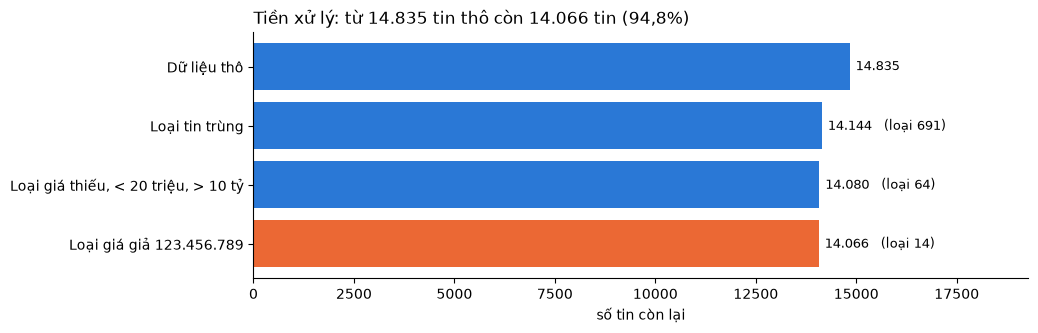

,bước,còn lại,loại bỏ
0,Dữ liệu thô,14835,0
1,Loại tin trùng,14144,691
2,"Loại giá thiếu, < 20 triệu, > 10 tỷ",14080,64
3,Loại giá giả 123.456.789,14066,14


In [26]:
steps = pd.DataFrame(FUNNEL, columns=["bước", "còn lại"])
steps["loại bỏ"] = (-steps["còn lại"].diff()).fillna(0).astype(int)
assert steps["còn lại"].iloc[-1] == len(clean)

fig, ax = plt.subplots(figsize=(10, 3.2))
y = np.arange(len(steps))[::-1]
ax.barh(y, steps["còn lại"], color=[BLUE] * (len(steps) - 1) + [ORANGE])
for yi, (_, r) in zip(y, steps.iterrows()):
    note = f"   (loại {vn(r['loại bỏ'])})" if r["loại bỏ"] else ""
    ax.text(r["còn lại"] + 150, yi, vn(r["còn lại"]) + note, va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(steps["bước"])
ax.set_xlim(0, steps["còn lại"].max() * 1.3); ax.set_xlabel("số tin còn lại")
ax.set_title(f"Tiền xử lý: từ {vn(steps['còn lại'].iloc[0])} tin thô còn {vn(len(clean))} tin "
             f"({vn(len(clean) / steps['còn lại'].iloc[0] * 100, 1)}%)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "p01_pheu_lam_sach"); plt.show()

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.barh(y, steps["còn lại"], color=[BLUE] * (len(steps) - 1) + [ORANGE], height=0.6)
    for yi, (_, r) in zip(y, steps.iterrows()):
        note = f"  (−{vn(r['loại bỏ'])})" if r["loại bỏ"] else ""
        ax.text(r["còn lại"] + 150, yi, vn(r["còn lại"]) + note, va="center", fontsize=13)
    ax.set_yticks(y); ax.set_yticklabels(steps["bước"])
    ax.set_xlim(0, steps["còn lại"].max() * 1.35); ax.set_xlabel("số tin còn lại")
    ax.set_title(f"Làm sạch bằng quy tắc cứng: giữ {vn(len(clean) / steps['còn lại'].iloc[0] * 100, 1)}% số tin")
    ax.grid(axis="y", visible=False)
    save_slide(fig, "p01_pheu_lam_sach"); plt.close(fig)

save_table(steps.set_index("bước"), "thong_ke_lam_sach", "Số tin còn lại qua từng bước làm sạch (preprocess)",
           part="preprocess", floatfmt=".0f",
           note="Bước lọc giá trả trước / đặt cọc nằm ở process_data (bảng thong_ke_xu_ly).")
steps

In [27]:
num_desc = clean[["price_tr", "age", "mileage_km", "carseats"]].describe().T.round(1)
num_desc.insert(0, "thiếu", clean[["price_tr", "age", "mileage_km", "carseats"]].isna().sum())
cat_cols = ["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", "province"]
cat_desc = pd.DataFrame({
    "số giá trị": clean[cat_cols].nunique(),
    "thiếu": clean[cat_cols].isna().sum(),
    "giá trị phổ biến nhất": clean[cat_cols].mode().iloc[0],
    "% phổ biến nhất": [round(clean[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in cat_cols],
})
save_table(num_desc, "thong_ke_mo_ta", "Thống kê mô tả biến số (sau tiền xử lý)", part="preprocess", floatfmt=".1f")
save_table(cat_desc, "thong_ke_mo_ta_phan_loai", "Thống kê mô tả biến phân loại (sau tiền xử lý)", part="preprocess",
           floatfmt=".1f")
update_numbers(so_tin_tho=len(raw), so_tin_sau_tien_xu_ly=len(clean),
               ti_le_giu_sau_tien_xu_ly=round(len(clean) / len(raw), 4), ngay_crawl="25/10/2026",
               so_hang=int(clean["carbrand"].nunique()),
               so_dong_xe=int((clean["carbrand"] + " " + clean["carmodel"]).nunique()))
display(num_desc)
cat_desc

,thiếu,count,mean,std,min,25%,50%,75%,max
price_tr,0,14066.0,600.1,659.8,20.0,280.0,455.0,680.0,9769.0
age,0,14066.0,7.0,6.2,0.0,2.0,5.0,10.0,47.0
mileage_km,826,13240.0,69950.9,62945.4,0.0,20000.0,61000.0,99999.0,500000.0
carseats,3552,10514.0,5.9,1.8,2.0,5.0,5.0,7.0,16.0


,số giá trị,thiếu,giá trị phổ biến nhất,% phổ biến nhất
carbrand,69,0,Toyota,20.2
carmodel,466,0,Innova,4.2
carorigin,11,0,Không rõ,41.5
condition_ad,2,0,Đã sử dụng,91.3
gearbox,3,0,Tự động,79.4
fuel,4,0,Xăng,72.7
cartype,9,4623,SUV / Cross over,40.3
province,63,0,tp-ho-chi-minh,49.4


## Tóm tắt các bước đã làm

| Mục | Bước | Học tham số từ dữ liệu? | Kết quả |
|---|---|---|---|
| 0 | Đọc code crawl: `N/A` = không có thẻ, cột chọn từ danh sách vs. gõ tự do, URL chứa vị trí | không | Biết mỗi loại lỗi đến từ đâu |
| 2 | Đổi `N/A`/`Đang cập nhật`/`Khác (carseats)` → thiếu thật, ép kiểu số | không | Cột số dùng được |
| 3 | Trích `province` từ URL; bỏ `no`, `url`, `veh_warranty_policy`; xóa dòng trùng (không xét vị trí) | không | Tránh trùng mẫu giữa train và test |
| 5 | Loại giá < 20 triệu hoặc > 10 tỷ, giá giả dạng `123.456.789`; số km vô lý → thiếu; xe "Mới" hơn 3 năm tuổi → "Đã sử dụng" | không (ngưỡng nghiệp vụ) | Bỏ lỗi nhập liệu, giữ xe sang thật |
| 6 | Xe mới: km = 0; `carorigin` thiếu → "Không rõ" | không (hằng số) | Còn thiếu ở km xe cũ, kiểu dáng, số chỗ |
| 7 | EDA: giá theo tuổi, hãng, số km, tương quan, kiểu dáng, hộp số | không (chỉ mô tả) | Định hướng log giá, `age²` cho Ridge, gộp nhãn, permutation importance |
| 8 | `price_log = ln(giá)`, `age = 2026 − năm` | không (công thức) | Biến mục tiêu gần đối xứng |
| 9 | Phân tích mất cân bằng theo phân khúc giá | không | Quyết định chia phân tầng, báo MAPE theo phân khúc |
| 10 | Xuất `preprocess_data.csv`, kiểm tra bằng `assert` | không | Còn `NaN` đúng ở 3 cột được phép |

**Chuyển sang `process_data.ipynb`** (học tham số, chỉ từ train): điền km xe cũ, kiểu dáng, số chỗ; gộp nhãn hiếm hãng / dòng xe; lọc giá trả trước / đặt cọc; tạo `km_per_year`, `mileage_missing` và các biến đổi cho Ridge; thí nghiệm chọn cách gộp nhãn và thử vị trí.